# EDA — Vietnamese Currency Detection Dataset (YOLOv8)

**Mục tiêu:** Hiểu dữ liệu trước khi học mô hình: mẫu là gì, nhãn ra sao, phân phối thế nào, có lệch/nhiễu/outlier không, và đặc trưng quan sát được trên ảnh mang tín hiệu gì cho bài nhận dạng mệnh giá.

**Nguồn dữ liệu:** Roboflow — `Vietnamese Currency.v1i.yolov8` (khoảng 2194 ảnh, định dạng YOLO).

**Cách tiếp cận EDA trong notebook này:**
1. Xác định đầu vào / đầu ra bài toán và cách đọc nhãn
2. Khảo sát quy mô, split và phân phối lớp
3. Kiểm tra chất lượng nhãn, hình học box và điều kiện ảnh
4. Làm rõ phạm vi lớp mục tiêu và quy tắc dùng train/valid/test
5. Biểu diễn sơ bộ đặc trưng màu/texture trên từng tờ tiền (crop) để định hướng model sau này
6. Tổng hợp nhận xét phục vụ huấn luyện và báo cáo


## Nguồn ảnh dùng cho huấn luyện (bổ sung báo cáo)

Báo cáo dùng hai nhóm nguồn ảnh:

| Nguồn | Vai trò | Ghi chú |
|------|---------|---------|
| **Roboflow — Vietnamese Currency** (xuất YOLOv8) | Train / Valid / Test chính | ~1537 / 439 / 218 ảnh; 9 lớp; CC BY 4.0 |
| **Ảnh camera thật** (`real_image/` → `datasets/real_cam_yolo/`) | Fine-tune thích nghi miền (v4) | ~18 ảnh gốc front/back, gán bbox thủ công |

**Liên kết tham chiếu nguồn mở / tham khảo thêm:**
- Roboflow Vietnamese Currency: https://universe.roboflow.com/first-qkz37/vietnamese-currency-lgi9i
- GitHub tien-giay-vn: https://github.com/vietanhdev/tien-giay-vn
- Kaggle Vietnamese Money: https://www.kaggle.com/datasets/huyphmnguyenthanh/vietnamese-money
- Roboflow Vietnamese Banknote: https://universe.roboflow.com/bao-vu/vietnamese-banknote

Ô code bên dưới thống kê nhanh số ảnh Roboflow và số ảnh camera thật (nếu có trên máy).


In [1]:
from pathlib import Path

PROJECT = Path('..').resolve().parent if (Path('..') / 'datasets').exists() else Path('../..').resolve()
# Khi chạy từ report/notebooks: project root = parents[1]
PROJECT = Path.cwd()
for cand in [Path.cwd().parents[1], Path.cwd().parent, Path('/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam')]:
    if (cand / 'datasets').exists() or (cand / 'Vietnamese Currency.v1i.yolov8').exists():
        PROJECT = cand
        break

robo = PROJECT / 'Vietnamese Currency.v1i.yolov8'
bbox = PROJECT / 'datasets' / 'vn_currency_yolo_bbox'
real = PROJECT / 'datasets' / 'real_cam_yolo'
real_raw = PROJECT / 'real_image'

def count_images(p: Path) -> int:
    if not p.exists():
        return 0
    return sum(1 for _ in p.glob('*') if _.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'})

rows = []
for name, base in [('Roboflow gốc', robo), ('YOLO bbox (train pipeline)', bbox)]:
    for split in ['train', 'valid', 'test']:
        n = count_images(base / split / 'images')
        rows.append({'nguon': name, 'split': split, 'so_anh': n})

n_real_yolo = count_images(real / 'images')
n_real_raw = count_images(real_raw)
rows.append({'nguon': 'Camera thật (YOLO)', 'split': 'train_extra', 'so_anh': n_real_yolo})
rows.append({'nguon': 'Camera thật (raw real_image)', 'split': 'raw', 'so_anh': n_real_raw})

import pandas as pd
df_src = pd.DataFrame(rows)
print('PROJECT =', PROJECT)
display(df_src)
print('\nGhi chú: ảnh camera thật được trộn/augment vào vòng fine-tune v4, không thay thế test Roboflow.')


PROJECT = /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam


,nguon,split,so_anh
0,Roboflow gốc,train,1537
1,Roboflow gốc,valid,439
2,Roboflow gốc,test,218
3,YOLO bbox (train pipeline),train,1537
4,YOLO bbox (train pipeline),valid,439
5,YOLO bbox (train pipeline),test,218
6,Camera thật (YOLO),train_extra,18
7,Camera thật (raw real_image),raw,18



Ghi chú: ảnh camera thật được trộn/augment vào vòng fine-tune v4, không thay thế test Roboflow.


## 0. Cài đặt / Import

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from PIL import Image, ImageDraw, ImageFont

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 1. Đường dẫn & đọc `data.yaml`

In [3]:
# Notebook nằm ở: .../nhan_dang_tien_Viet_Nam/notebooks/
# Dataset nằm ở:  .../nhan_dang_tien_Viet_Nam/Vietnamese Currency.v1i.yolov8/
PROJECT_DIR = Path("..").resolve()
DATA_DIR = PROJECT_DIR / "Vietnamese Currency.v1i.yolov8"
YAML_PATH = DATA_DIR / "data.yaml"

assert DATA_DIR.exists(), f"Không tìm thấy dataset: {DATA_DIR}"
assert YAML_PATH.exists(), f"Không tìm thấy data.yaml: {YAML_PATH}"

with open(YAML_PATH, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

CLASS_NAMES = list(data_cfg["names"])
NC = int(data_cfg.get("nc", len(CLASS_NAMES)))
SPLITS = ["train", "valid", "test"]

print("DATA_DIR :", DATA_DIR)
print("nc       :", NC)
print("classes  :", CLASS_NAMES)
print("roboflow :", data_cfg.get("roboflow", {}))

AssertionError: Không tìm thấy dataset: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/report/Vietnamese Currency.v1i.yolov8

## 2. Đọc và chuẩn hóa nhãn YOLO

Nhãn được xuất theo YOLO nhưng **không đồng nhất hoàn toàn**:
- **BBox:** `class_id x_center y_center width height` (4 số)
- **Polygon:** `class_id x1 y1 x2 y2 ...` (≥ 6 số) → quy về bbox bao bằng min/max

Tọa độ đã **chuẩn hóa về [0, 1]** theo kích thước ảnh. Việc parse thống nhất ngay từ đầu giúp mọi thống kê EDA sau này cùng một định nghĩa object.


In [ ]:
def parse_yolo_line(line: str):
    """Parse 1 dòng nhãn YOLO → dict (class_id, bbox chuẩn hóa, ann_type)."""
    parts = line.strip().split()
    if len(parts) < 5:
        raise ValueError(f"Dòng nhãn không hợp lệ: {line!r}")

    class_id = int(float(parts[0]))
    coords = [float(x) for x in parts[1:]]

    if len(coords) == 4:
        xc, yc, w, h = coords
        ann_type = "bbox"
    else:
        # Polygon: chuyển thành bbox bao quanh
        if len(coords) % 2 != 0:
            raise ValueError(f"Polygon có số tọa độ lẻ: {line!r}")
        xs = coords[0::2]
        ys = coords[1::2]
        x_min, x_max = min(xs), max(xs)
        y_min, y_max = min(ys), max(ys)
        w = x_max - x_min
        h = y_max - y_min
        xc = (x_min + x_max) / 2
        yc = (y_min + y_max) / 2
        ann_type = "polygon"

    return {
        "class_id": class_id,
        "class_name": CLASS_NAMES[class_id] if 0 <= class_id < len(CLASS_NAMES) else f"unknown_{class_id}",
        "xc": xc,
        "yc": yc,
        "w": w,
        "h": h,
        "ann_type": ann_type,
        "n_coords": len(coords),
    }


def yolo_to_xyxy(xc, yc, w, h, img_w, img_h):
    """Chuẩn hóa YOLO → pixel (x1, y1, x2, y2)."""
    bw, bh = w * img_w, h * img_h
    cx, cy = xc * img_w, yc * img_h
    x1 = cx - bw / 2
    y1 = cy - bh / 2
    x2 = cx + bw / 2
    y2 = cy + bh / 2
    return x1, y1, x2, y2


def load_dataset(data_dir: Path, splits=None) -> pd.DataFrame:
    """Đọc toàn bộ ảnh + nhãn thành DataFrame mức object."""
    splits = splits or SPLITS
    rows = []

    for split in splits:
        img_dir = data_dir / split / "images"
        lbl_dir = data_dir / split / "labels"
        image_paths = sorted(
            list(img_dir.glob("*.jpg"))
            + list(img_dir.glob("*.jpeg"))
            + list(img_dir.glob("*.png"))
            + list(img_dir.glob("*.JPG"))
            + list(img_dir.glob("*.JPEG"))
            + list(img_dir.glob("*.PNG"))
        )

        for img_path in image_paths:
            lbl_path = lbl_dir / f"{img_path.stem}.txt"
            with Image.open(img_path) as im:
                img_w, img_h = im.size

            if not lbl_path.exists():
                rows.append({
                    "split": split,
                    "image": img_path.name,
                    "image_path": str(img_path),
                    "label_path": str(lbl_path),
                    "img_w": img_w,
                    "img_h": img_h,
                    "class_id": np.nan,
                    "class_name": None,
                    "xc": np.nan,
                    "yc": np.nan,
                    "w": np.nan,
                    "h": np.nan,
                    "ann_type": "missing_label",
                    "n_coords": np.nan,
                    "n_objects": 0,
                })
                continue

            lines = [ln for ln in lbl_path.read_text(encoding="utf-8").splitlines() if ln.strip()]
            if not lines:
                rows.append({
                    "split": split,
                    "image": img_path.name,
                    "image_path": str(img_path),
                    "label_path": str(lbl_path),
                    "img_w": img_w,
                    "img_h": img_h,
                    "class_id": np.nan,
                    "class_name": None,
                    "xc": np.nan,
                    "yc": np.nan,
                    "w": np.nan,
                    "h": np.nan,
                    "ann_type": "empty",
                    "n_coords": np.nan,
                    "n_objects": 0,
                })
                continue

            parsed = [parse_yolo_line(ln) for ln in lines]
            for obj in parsed:
                rows.append({
                    "split": split,
                    "image": img_path.name,
                    "image_path": str(img_path),
                    "label_path": str(lbl_path),
                    "img_w": img_w,
                    "img_h": img_h,
                    "n_objects": len(parsed),
                    **obj,
                })

    return pd.DataFrame(rows)

print("Đã định nghĩa parse_yolo_line / load_dataset")

Đã định nghĩa parse_yolo_line / load_dataset


## 3. Load toàn bộ dataset

In [ ]:
df = load_dataset(DATA_DIR)

# Bảng mức ảnh (1 dòng / ảnh)
df_img = (
    df.groupby(["split", "image", "image_path", "img_w", "img_h"], as_index=False)
      .agg(
          n_objects=("n_objects", "max"),
          n_classes=("class_name", "nunique"),
          ann_types=("ann_type", lambda s: ",".join(sorted(set(s.dropna().astype(str))))),
      )
)

print(f"Tổng số dòng (object-level): {len(df):,}")
print(f"Tổng số ảnh                : {len(df_img):,}")
print(f"Tổng số object có nhãn     : {df['class_id'].notna().sum():,}")
display(df.head())
display(df_img.head())


Tổng số dòng (object-level): 5,464
Tổng số ảnh                : 2,194
Tổng số object có nhãn     : 5,464


,split,image,image_path,label_path,img_w,img_h,n_objects,class_id,class_name,xc,yc,w,h,ann_type,n_coords
0,train,006769ea-071e-43ea-9165-7ed6cee7b9d6_jpg.rf.a0...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,1,8,500000,0.512664,0.558000,0.535022,0.884000,polygon,10
1,train,014bce1a-c772-4522-8cb9-c0f58047a815_jpg.rf.d8...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,1,5,200000,0.512664,0.569576,0.894074,0.501481,polygon,10
2,train,02890660-7b1b-4cbf-a919-143160d5e225_jpg.rf.f3...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,1,5,200000,0.506832,0.492165,0.937178,0.448132,polygon,10
3,train,028a3558-75f2-48ba-ab57-6e5ff796e8b6_jpg.rf.a3...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,1,4,20000,0.563281,0.536719,0.870313,0.926562,bbox,4
4,train,0573bcda-312d-454a-ba26-d05741d774d8_jpg.rf.c8...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,1,5,200000,0.504881,0.525508,0.842429,0.397450,polygon,10


,split,image,image_path,img_w,img_h,n_objects,n_classes,ann_types
0,test,1101_jpg.rf.06df46eaafe6613b9d89212653907777.jpg,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,3,3,bbox
1,test,1104_jpg.rf.3faa2a95631ae4a9218014dfdd6cb55c.jpg,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,3,3,bbox
2,test,1115_jpg.rf.92386af30f35bde44adfb205681970c4.jpg,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,3,3,bbox
3,test,1122_jpg.rf.14605dd2a0458d904db3c5955e45c5ea.jpg,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,3,3,bbox
4,test,1128_jpg.rf.b6edad43db6c00616b44d36089760ff0.jpg,/home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_ma...,640,640,3,3,bbox


## 4. Quy mô dữ liệu theo split và kích thước ảnh

Bước đầu của hồ sơ dữ liệu: có bao nhiêu mẫu ở mỗi tập, tỷ lệ train/valid/test có hợp lý không, và kích thước ảnh có đồng nhất sau tiền xử lý không.


,split,n_images,n_objects,pct_images,objects_per_image
0,train,1537,3832,70.05,2.49
1,valid,439,1074,20.01,2.45
2,test,218,558,9.94,2.56


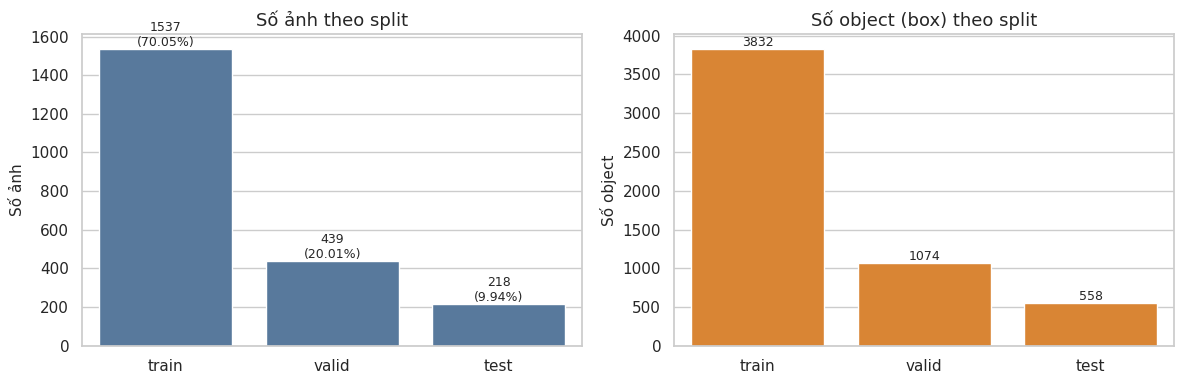

Phân bố kích thước ảnh (pixel):


,count,mean,std,min,25%,50%,75%,max
img_w,2194.0,640.0,0.0,640.0,640.0,640.0,640.0,640.0
img_h,2194.0,640.0,0.0,640.0,640.0,640.0,640.0,640.0


Số cặp (img_w, img_h) duy nhất: 1


In [ ]:
split_summary = (
    df_img.groupby("split", as_index=False)
          .agg(n_images=("image", "count"), n_objects=("n_objects", "sum"))
)
split_summary["pct_images"] = (100 * split_summary["n_images"] / split_summary["n_images"].sum()).round(2)
split_summary["objects_per_image"] = (split_summary["n_objects"] / split_summary["n_images"]).round(2)

# Giữ thứ tự train → valid → test
split_order = [s for s in SPLITS if s in set(split_summary["split"])]
split_summary["split"] = pd.Categorical(split_summary["split"], categories=split_order, ordered=True)
split_summary = split_summary.sort_values("split").reset_index(drop=True)

display(split_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=split_summary, x="split", y="n_images", ax=axes[0], color="#4C78A8")
axes[0].set_title("Số ảnh theo split")
axes[0].set_xlabel("")
axes[0].set_ylabel("Số ảnh")
for i, row in split_summary.iterrows():
    axes[0].text(i, row["n_images"], f'{int(row["n_images"])}\n({row["pct_images"]}%)',
                 ha="center", va="bottom", fontsize=9)

sns.barplot(data=split_summary, x="split", y="n_objects", ax=axes[1], color="#F58518")
axes[1].set_title("Số object (box) theo split")
axes[1].set_xlabel("")
axes[1].set_ylabel("Số object")
for i, row in split_summary.iterrows():
    axes[1].text(i, row["n_objects"], f'{int(row["n_objects"])}',
                 ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

print("Phân bố kích thước ảnh (pixel):")
display(df_img[["img_w", "img_h"]].describe().T)
print("Số cặp (img_w, img_h) duy nhất:", df_img.groupby(["img_w", "img_h"]).ngroups)

## 5. Phân phối nhãn theo mệnh giá

Kiểm tra cân bằng lớp vì ảnh hưởng trực tiếp tới lỗi bỏ sót/nhầm lớp.  
Nếu một mệnh giá quá ít, metric tổng có thể che mất hiệu năng kém trên lớp hiếm.


,class_name,n_boxes,pct
0,1000,604,11.05
1,2000,607,11.11
2,5000,609,11.15
3,10000,609,11.15
4,20000,603,11.04
5,50000,620,11.35
6,100000,609,11.15
7,200000,602,11.02
8,500000,601,11.00


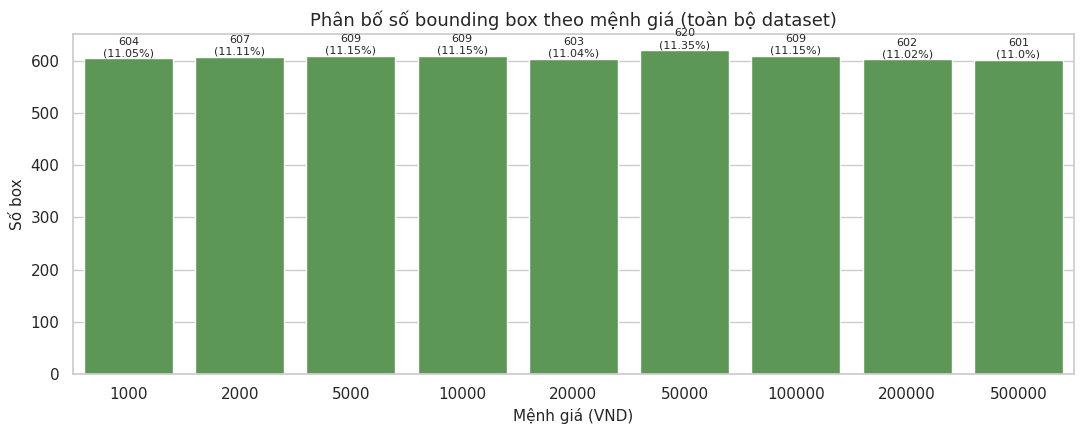

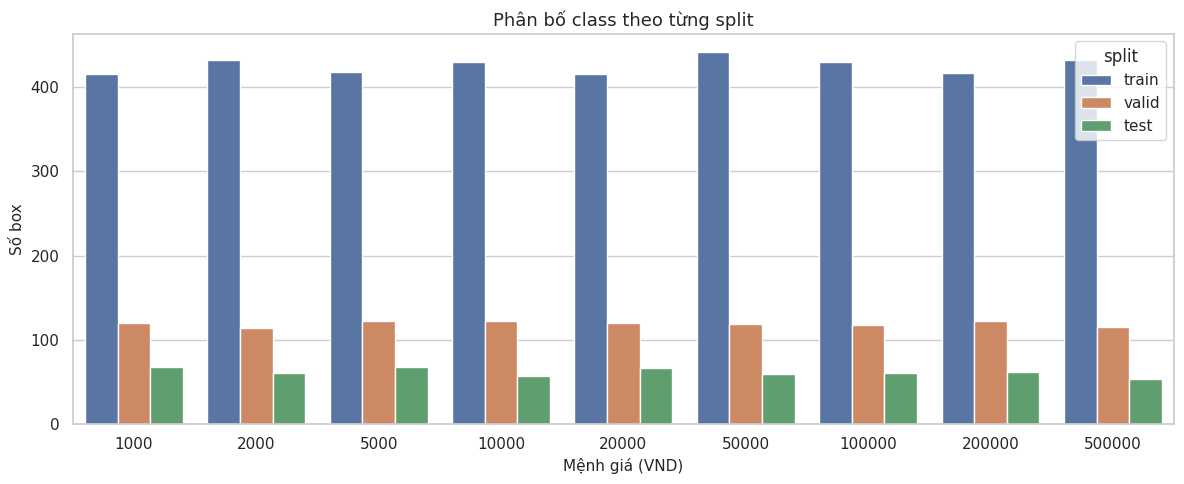

Class trong data.yaml     : ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']
Class README đề cập       : ['500', '1000', '2000', '5000', '10000', '20000', '50000', '100000', '200000', '500000']
Thiếu so với README       : ['500']
Thừa so với README        : (không)


In [ ]:
df_obj = df[df["class_id"].notna()].copy()

# Thứ tự class theo mệnh giá tăng dần (dễ đọc hơn thứ tự trong data.yaml)
denom_order = sorted(CLASS_NAMES, key=lambda x: int(x))

class_overall = (
    df_obj.groupby("class_name", as_index=False)
          .size()
          .rename(columns={"size": "n_boxes"})
)
class_overall["class_name"] = pd.Categorical(class_overall["class_name"], categories=denom_order, ordered=True)
class_overall = class_overall.sort_values("class_name").reset_index(drop=True)
class_overall["pct"] = (100 * class_overall["n_boxes"] / class_overall["n_boxes"].sum()).round(2)

display(class_overall)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=class_overall, x="class_name", y="n_boxes", ax=ax, color="#54A24B")
ax.set_title("Phân bố số bounding box theo mệnh giá (toàn bộ dataset)")
ax.set_xlabel("Mệnh giá (VND)")
ax.set_ylabel("Số box")
for i, row in class_overall.iterrows():
    ax.text(i, row["n_boxes"], f'{int(row["n_boxes"])}\n({row["pct"]}%)',
            ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

# So sánh theo split
class_by_split = (
    df_obj.groupby(["split", "class_name"], as_index=False)
          .size()
          .rename(columns={"size": "n_boxes"})
)
class_by_split["class_name"] = pd.Categorical(class_by_split["class_name"], categories=denom_order, ordered=True)
class_by_split["split"] = pd.Categorical(class_by_split["split"], categories=split_order, ordered=True)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=class_by_split, x="class_name", y="n_boxes", hue="split", ax=ax)
ax.set_title("Phân bố class theo từng split")
ax.set_xlabel("Mệnh giá (VND)")
ax.set_ylabel("Số box")
ax.legend(title="split")
plt.tight_layout()
plt.show()

# Class kỳ vọng theo README đề tài nhưng thiếu trong data.yaml
expected_readme = ["500", "1000", "2000", "5000", "10000", "20000", "50000", "100000", "200000", "500000"]
missing = [c for c in expected_readme if c not in CLASS_NAMES]
extra = [c for c in CLASS_NAMES if c not in expected_readme]
print("Class trong data.yaml     :", CLASS_NAMES)
print("Class README đề cập       :", expected_readme)
print("Thiếu so với README       :", missing if missing else "(không)")
print("Thừa so với README        :", extra if extra else "(không)")

## 6. Độ phức tạp của ảnh: số object trên mỗi ảnh

Ảnh một tờ khác ảnh nhiều tờ về độ khó định vị và chồng lấn.  
Phân phối này giúp giải thích sau này vì sao một số lỗi xuất hiện trên ảnh đông object.


,n_objects,n_images,pct
0,1,905,41.25
1,2,4,0.18
2,3,874,39.84
3,4,126,5.74
4,5,285,12.99


Trung bình object/ảnh: 2.49 | median=3 | min=1 | max=5
Ảnh không có object     : 0
Ảnh có ≥2 class khác nhau: 1285 (58.6%)


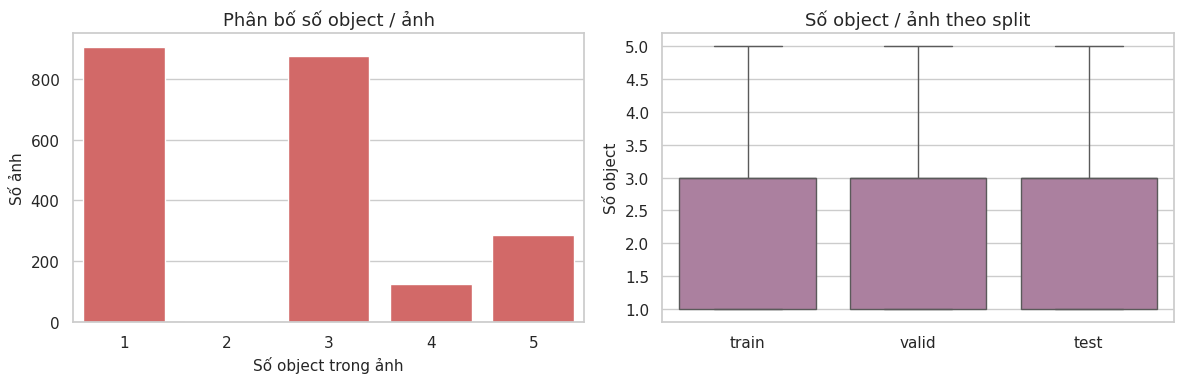

In [ ]:
obj_count_dist = (
    df_img.groupby("n_objects", as_index=False)
          .size()
          .rename(columns={"size": "n_images"})
          .sort_values("n_objects")
)
obj_count_dist["pct"] = (100 * obj_count_dist["n_images"] / obj_count_dist["n_images"].sum()).round(2)

display(obj_count_dist)
print(
    f"Trung bình object/ảnh: {df_img['n_objects'].mean():.2f} | "
    f"median={df_img['n_objects'].median():.0f} | "
    f"min={df_img['n_objects'].min()} | max={df_img['n_objects'].max()}"
)
print(f"Ảnh không có object     : {(df_img['n_objects'] == 0).sum()}")
print(f"Ảnh có ≥2 class khác nhau: {(df_img['n_classes'] >= 2).sum()} "
      f"({100 * (df_img['n_classes'] >= 2).mean():.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=obj_count_dist, x="n_objects", y="n_images", ax=axes[0], color="#E45756")
axes[0].set_title("Phân bố số object / ảnh")
axes[0].set_xlabel("Số object trong ảnh")
axes[0].set_ylabel("Số ảnh")

sns.boxplot(data=df_img, x="split", y="n_objects", order=split_order, ax=axes[1], color="#B279A2")
axes[1].set_title("Số object / ảnh theo split")
axes[1].set_xlabel("")
axes[1].set_ylabel("Số object")

plt.tight_layout()
plt.show()

## 7. Kiểm tra tính nhất quán của kiểu annotation

Trước khi học, cần biết nhãn đang ở dạng nào và tỷ lệ mỗi dạng.  
Lẫn bbox/polygon không sai tuyệt đối, nhưng phải được xử lý có kiểm soát trong pipeline.


,ann_type,n_objects,pct
0,bbox,3810,69.73
1,polygon,1654,30.27


,n_coords,n_objects
0,4,3810
1,10,1561
2,12,53
3,14,26
4,16,8
5,18,3
6,20,1
7,24,1
8,30,1


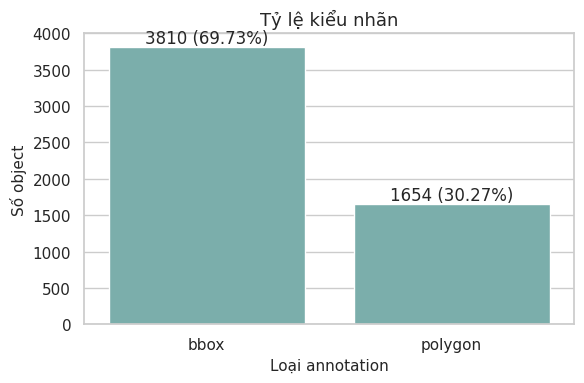

Ghi chú: Với object detection (YOLO detect), polygon đã được chuyển về bbox bao quanh.
Nếu train segmentation thì giữ polygon; nếu train detection thuần bbox thì nên export lại
hoặc convert toàn bộ về 4 giá trị xc yc w h trước khi train.


In [ ]:
ann_summary = (
    df_obj.groupby("ann_type", as_index=False)
          .size()
          .rename(columns={"size": "n_objects"})
)
ann_summary["pct"] = (100 * ann_summary["n_objects"] / ann_summary["n_objects"].sum()).round(2)
display(ann_summary)

coord_dist = (
    df_obj.groupby("n_coords", as_index=False)
          .size()
          .rename(columns={"size": "n_objects"})
          .sort_values("n_coords")
)
display(coord_dist)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=ann_summary, x="ann_type", y="n_objects", ax=ax, color="#72B7B2")
ax.set_title("Tỷ lệ kiểu nhãn")
ax.set_xlabel("Loại annotation")
ax.set_ylabel("Số object")
for i, row in ann_summary.iterrows():
    ax.text(i, row["n_objects"], f'{int(row["n_objects"])} ({row["pct"]}%)',
            ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(
    "Ghi chú: Với object detection (YOLO detect), polygon đã được chuyển về bbox bao quanh.\n"
    "Nếu train segmentation thì giữ polygon; nếu train detection thuần bbox thì nên export lại\n"
    "hoặc convert toàn bộ về 4 giá trị xc yc w h trước khi train."
)

## 8. Phân tích hình học bounding box

Xem phân phối kích thước và tỷ lệ khung hình của object:
- `area_norm = w * h` (diện tích tương đối trên ảnh)
- `aspect_ratio = w / h` (tờ tiền thường ngang; ảnh xoay/dọc có thể khác)

Các phân phối này vừa mô tả dữ liệu, vừa là đầu vào để phát hiện ngoại lệ ở mục sau.


,count,mean,std,min,25%,50%,75%,max
w,5464.0,0.3107,0.2251,0.0016,0.1606,0.2406,0.3611,1.0000
h,5464.0,0.2552,0.2055,0.0016,0.1344,0.1928,0.2750,1.0000
area_norm,5464.0,0.1063,0.1576,0.0000,0.0223,0.0444,0.0775,1.0000
aspect_ratio,5464.0,1.4210,0.7006,0.1667,0.6496,1.5917,1.9266,6.0652
box_w_px,5464.0,198.8275,144.0604,1.0000,102.8108,154.0000,231.1219,640.0000
box_h_px,5464.0,163.3105,131.5379,1.0000,86.0000,123.3866,176.0000,640.0000


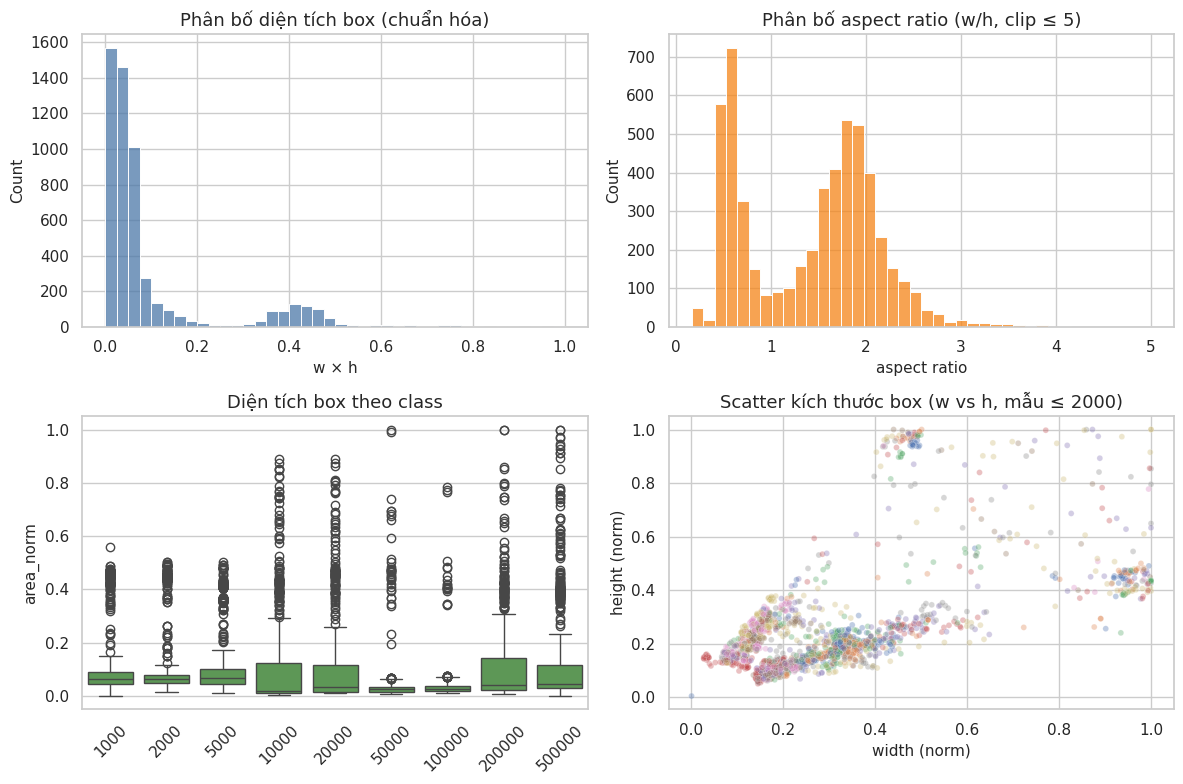

Box rất nhỏ (area_norm < 0.01): 129 (2.36%)
Box rất lớn (area_norm > 0.50): 138 (2.53%)


In [ ]:
geo = df_obj.copy()
geo["area_norm"] = geo["w"] * geo["h"]
geo["aspect_ratio"] = geo["w"] / geo["h"].replace(0, np.nan)
geo["box_w_px"] = geo["w"] * geo["img_w"]
geo["box_h_px"] = geo["h"] * geo["img_h"]

display(geo[["w", "h", "area_norm", "aspect_ratio", "box_w_px", "box_h_px"]].describe().T.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(geo["area_norm"], bins=40, ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Phân bố diện tích box (chuẩn hóa)")
axes[0, 0].set_xlabel("w × h")

sns.histplot(geo["aspect_ratio"].clip(upper=5), bins=40, ax=axes[0, 1], color="#F58518")
axes[0, 1].set_title("Phân bố aspect ratio (w/h, clip ≤ 5)")
axes[0, 1].set_xlabel("aspect ratio")

sns.boxplot(
    data=geo, x="class_name", y="area_norm",
    order=denom_order, ax=axes[1, 0], color="#54A24B"
)
axes[1, 0].set_title("Diện tích box theo class")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].set_xlabel("")

sns.scatterplot(
    data=geo.sample(min(2000, len(geo)), random_state=RANDOM_SEED),
    x="w", y="h", hue="class_name", hue_order=denom_order,
    alpha=0.35, s=18, ax=axes[1, 1], legend=False
)
axes[1, 1].set_title("Scatter kích thước box (w vs h, mẫu ≤ 2000)")
axes[1, 1].set_xlabel("width (norm)")
axes[1, 1].set_ylabel("height (norm)")

plt.tight_layout()
plt.show()

# Box quá nhỏ / quá lớn — hữu ích khi phân tích lỗi sau này
small = geo[geo["area_norm"] < 0.01]
large = geo[geo["area_norm"] > 0.5]
print(f"Box rất nhỏ (area_norm < 0.01): {len(small)} ({100 * len(small) / len(geo):.2f}%)")
print(f"Box rất lớn (area_norm > 0.50): {len(large)} ({100 * len(large) / len(geo):.2f}%)")

## 9. Mật độ vị trí tâm object trên khung ảnh

Kiểm tra object có bị thiên về một vùng ảnh không (ví dụ luôn nằm giữa, hoặc tránh vùng letterbox).  
Thiên lệch vị trí là một dạng lệch lấy mẫu cần ghi nhận.


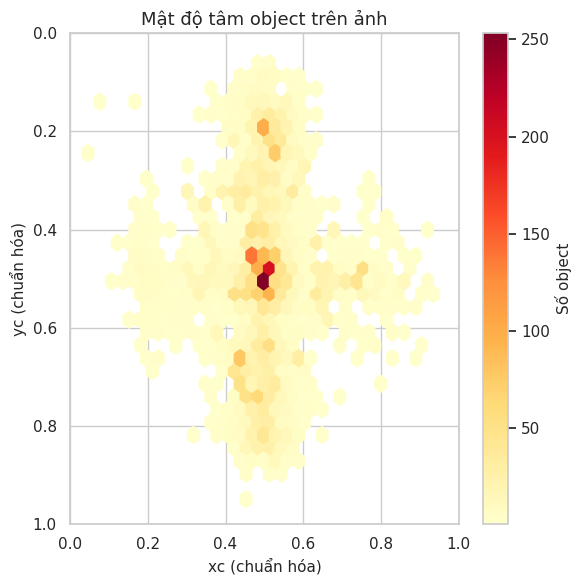

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
hb = ax.hexbin(geo["xc"], geo["yc"], gridsize=30, cmap="YlOrRd", mincnt=1)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)  # gốc ảnh thường ở góc trên-trái
ax.set_xlabel("xc (chuẩn hóa)")
ax.set_ylabel("yc (chuẩn hóa)")
ax.set_title("Mật độ tâm object trên ảnh")
cb = fig.colorbar(hb, ax=ax)
cb.set_label("Số object")
plt.tight_layout()
plt.show()

## 10. Quan sát trực tiếp ảnh kèm nhãn

Số liệu cần được đối chiếu với ảnh thật: box có ôm sát tờ tiền không, class có đúng không, ảnh nhiều object có bị thiếu nhãn không.


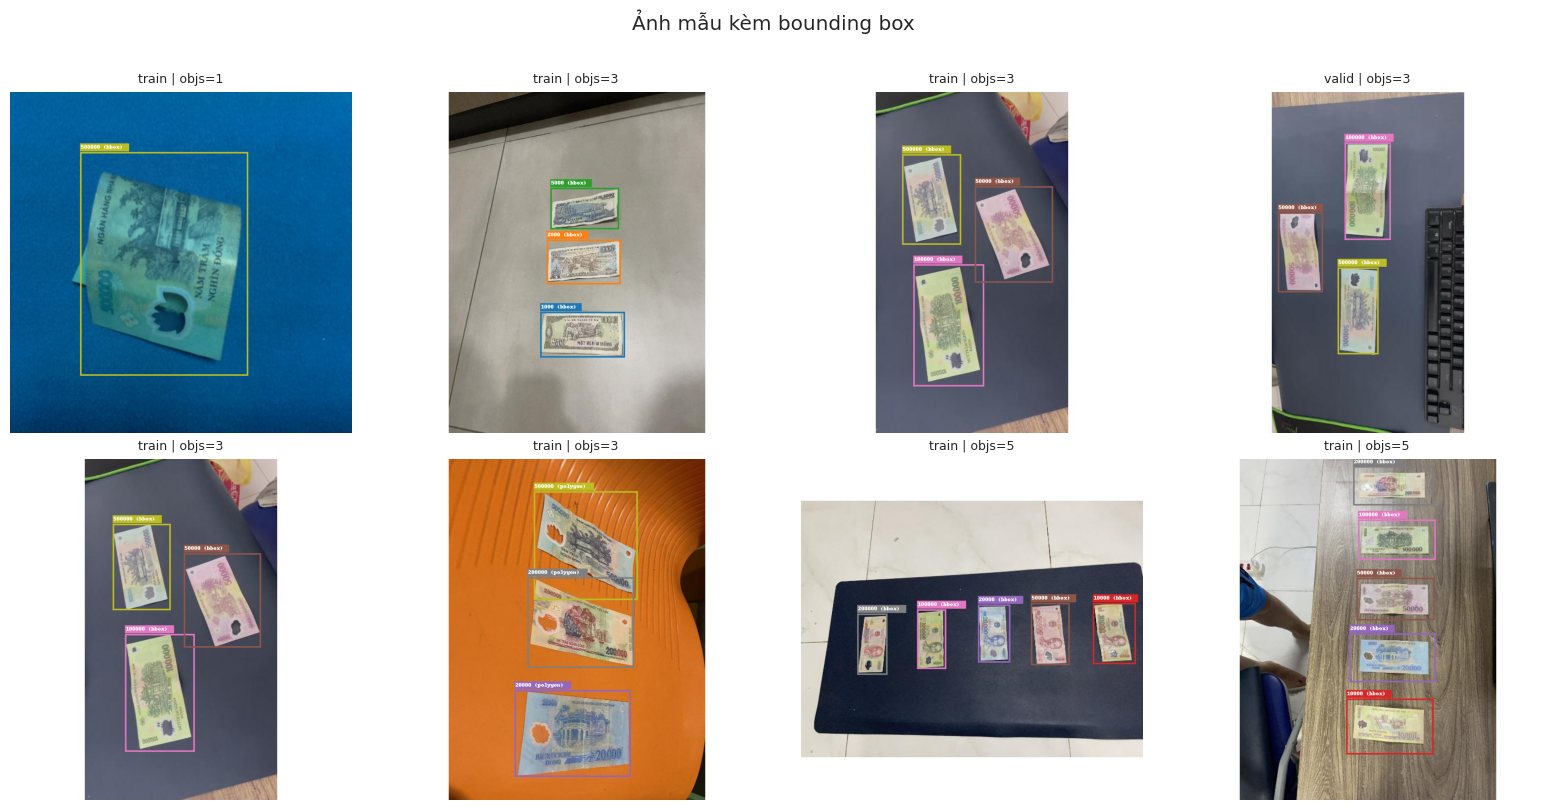

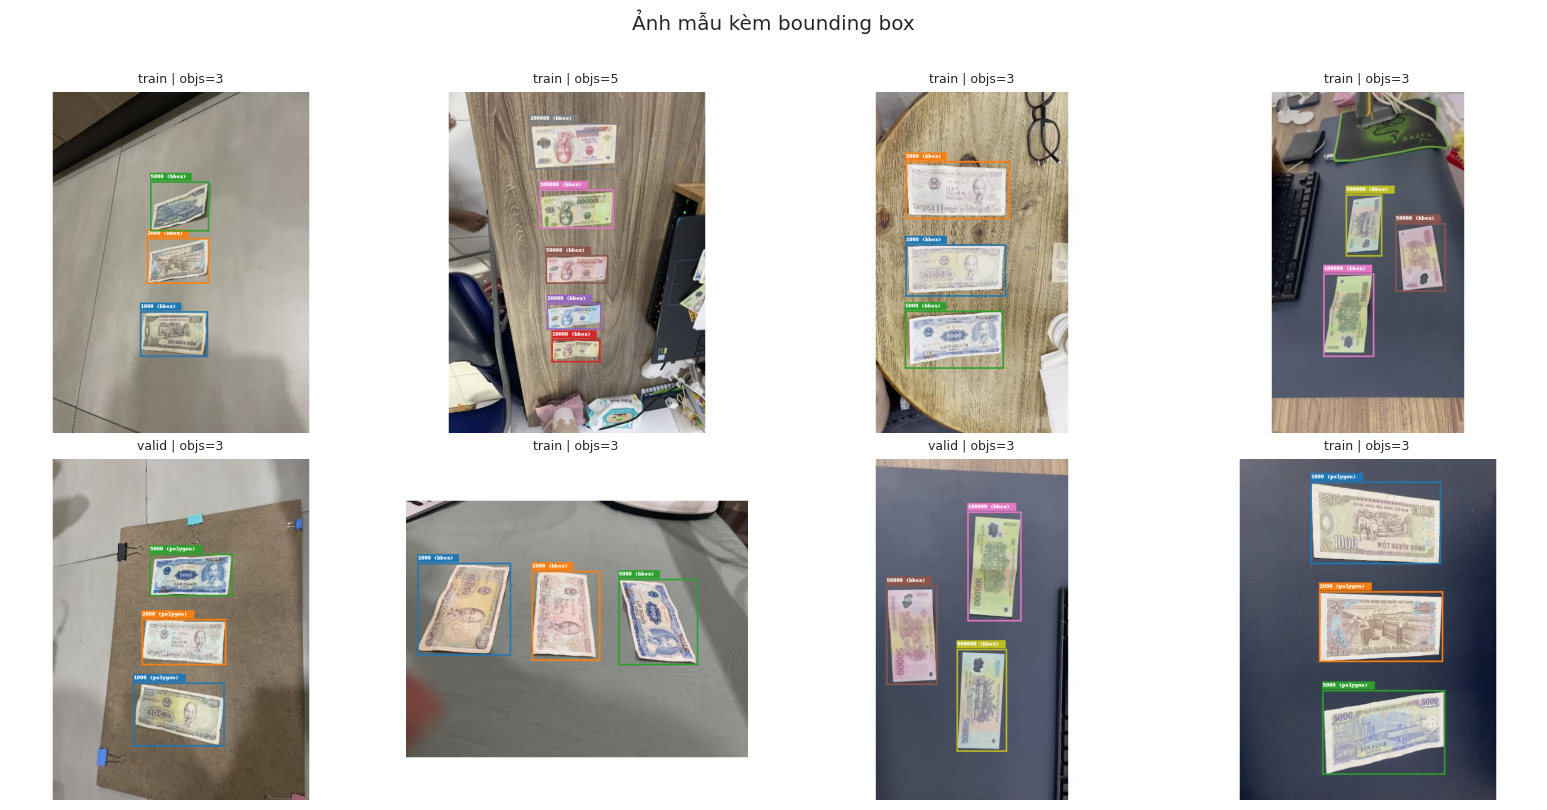

In [ ]:
# Pallete màu ổn định theo class
palette = sns.color_palette("tab10", n_colors=max(NC, 3))
COLOR_MAP = {
    name: tuple(int(255 * c) for c in palette[i % len(palette)])
    for i, name in enumerate(denom_order)
}


def draw_boxes(image_path: str, ann_df: pd.DataFrame):
    """Vẽ bbox + class lên ảnh PIL."""
    im = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(im)
    img_w, img_h = im.size

    for _, r in ann_df.iterrows():
        if pd.isna(r["class_id"]):
            continue
        x1, y1, x2, y2 = yolo_to_xyxy(r["xc"], r["yc"], r["w"], r["h"], img_w, img_h)
        color = COLOR_MAP.get(r["class_name"], (255, 0, 0))
        draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
        label = f"{r['class_name']} ({r['ann_type']})"
        # nền chữ đơn giản
        tw = 7 * len(label)
        th = 14
        tx1, ty1 = x1, max(0, y1 - th - 2)
        draw.rectangle([tx1, ty1, tx1 + tw, ty1 + th], fill=color)
        draw.text((tx1 + 2, ty1 + 1), label, fill=(255, 255, 255))
    return im


def show_samples(df_all: pd.DataFrame, n=8, split=None, min_objects=1, seed=RANDOM_SEED):
    subset_img = df_img.copy()
    if split is not None:
        subset_img = subset_img[subset_img["split"] == split]
    subset_img = subset_img[subset_img["n_objects"] >= min_objects]

    if subset_img.empty:
        print("Không có ảnh thỏa điều kiện.")
        return

    sample = subset_img.sample(n=min(n, len(subset_img)), random_state=seed)
    cols = 4
    rows = int(np.ceil(len(sample) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, img_row) in zip(axes, sample.iterrows()):
        ann = df_all[df_all["image"] == img_row["image"]]
        vis = draw_boxes(img_row["image_path"], ann)
        ax.imshow(vis)
        ax.set_title(f'{img_row["split"]} | objs={int(img_row["n_objects"])}', fontsize=9)
        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")

    plt.suptitle("Ảnh mẫu kèm bounding box", y=1.01)
    plt.tight_layout()
    plt.show()


# Ảnh ngẫu nhiên
show_samples(df, n=8, min_objects=1)

# Ưu tiên ảnh nhiều tờ (khó hơn)
show_samples(df, n=8, min_objects=3, seed=0)

## 11. Sanity check theo từng mệnh giá

Lấy ngẫu nhiên ảnh chứa từng class để xác nhận trực quan rằng nhãn và ngoại hình mệnh giá khớp nhau trước khi tin các thống kê tổng hợp.


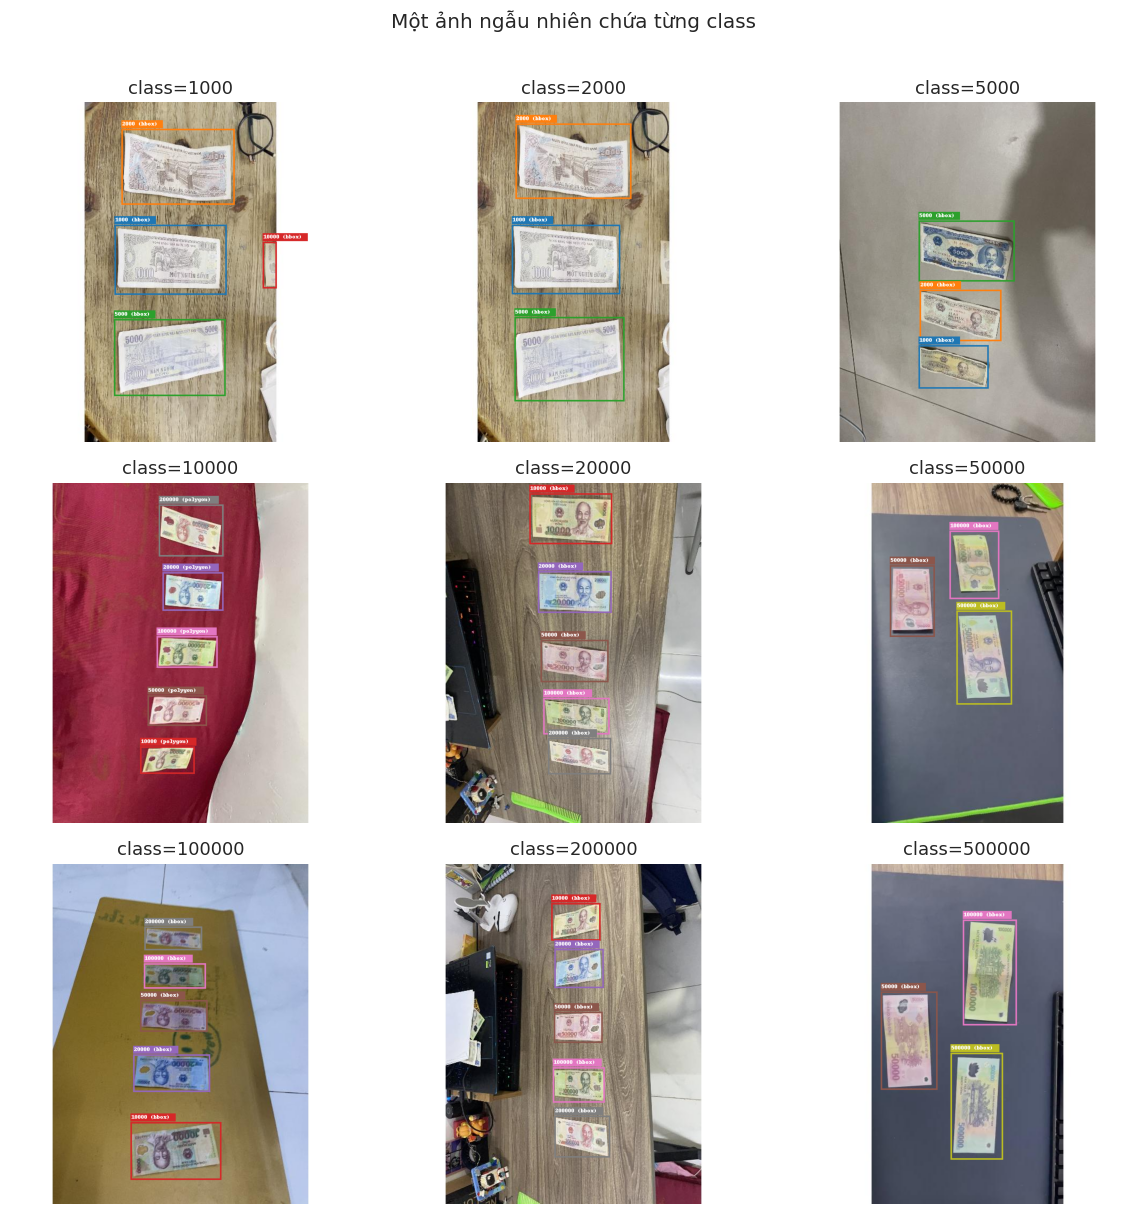

In [ ]:
def show_one_per_class(df_all: pd.DataFrame, seed=RANDOM_SEED):
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.ravel()

    for ax, cls in zip(axes, denom_order):
        cand = df_all[df_all["class_name"] == cls]
        if cand.empty:
            ax.set_title(f"{cls}: không có mẫu")
            ax.axis("off")
            continue
        row = cand.sample(1, random_state=seed).iloc[0]
        ann = df_all[df_all["image"] == row["image"]]
        vis = draw_boxes(row["image_path"], ann)
        ax.imshow(vis)
        ax.set_title(f"class={cls}")
        ax.axis("off")

    for ax in axes[len(denom_order):]:
        ax.axis("off")

    plt.suptitle("Một ảnh ngẫu nhiên chứa từng class", y=1.01)
    plt.tight_layout()
    plt.show()


show_one_per_class(df_obj)

## 12. Kiểm tra nhanh lỗi kỹ thuật của nhãn

Rà các lỗi “cứng” có thể phá huấn luyện: thiếu file nhãn, `class_id` ngoài phạm vi, tọa độ vượt [0, 1], kích thước box không dương, lệch cặp ảnh–nhãn.


In [ ]:
issues = []

# 1) Ảnh thiếu file nhãn / nhãn rỗng
n_missing = (df_img["n_objects"] == 0).sum()
issues.append({"check": "Ảnh không có object", "count": int(n_missing)})

# 2) class_id ngoài [0, nc)
bad_id = df_obj[(df_obj["class_id"] < 0) | (df_obj["class_id"] >= NC)]
issues.append({"check": "class_id ngoài phạm vi", "count": int(len(bad_id))})

# 3) Tọa độ ngoài [0, 1] (cho phép sai số nhỏ do float)
eps = 1e-3
oob = df_obj[
    (df_obj["xc"] < -eps) | (df_obj["xc"] > 1 + eps) |
    (df_obj["yc"] < -eps) | (df_obj["yc"] > 1 + eps) |
    (df_obj["w"] < -eps) | (df_obj["w"] > 1 + eps) |
    (df_obj["h"] < -eps) | (df_obj["h"] > 1 + eps)
]
issues.append({"check": "Tọa độ bbox ngoài [0,1] (nới ±1e-3)", "count": int(len(oob))})

# 4) w/h ≤ 0
nonpos = df_obj[(df_obj["w"] <= 0) | (df_obj["h"] <= 0)]
issues.append({"check": "w hoặc h ≤ 0", "count": int(len(nonpos))})

# 5) Ảnh có nhãn nhưng thiếu file ảnh? (đã load từ images nên thường = 0)
label_stems = set()
image_stems = set()
for split in SPLITS:
    label_stems |= {p.stem for p in (DATA_DIR / split / "labels").glob("*.txt")}
    image_stems |= {p.stem for p in (DATA_DIR / split / "images").glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
issues.append({"check": "Label không có ảnh tương ứng", "count": len(label_stems - image_stems)})
issues.append({"check": "Ảnh không có label tương ứng", "count": len(image_stems - label_stems)})

issues_df = pd.DataFrame(issues)
display(issues_df)

if len(oob) > 0:
    print("Ví dụ tọa độ ngoài biên:")
    display(oob[["split", "image", "class_name", "xc", "yc", "w", "h"]].head())

,check,count
0,Ảnh không có object,0
1,class_id ngoài phạm vi,0
2,"Tọa độ bbox ngoài [0,1] (nới ±1e-3)",0
3,w hoặc h ≤ 0,0
4,Label không có ảnh tương ứng,0
5,Ảnh không có label tương ứng,0


## 13. Đơn vị quan sát & hồ sơ dữ liệu

Trước khi đếm mẫu hay tạo đặc trưng, cần chốt rõ **một quan sát đại diện cho cái gì**.

Bài toán detection dùng đồng thời hai cấp:
- **Mức ảnh:** một file ảnh có thể chứa nhiều tờ tiền → đơn vị đầu vào của mô hình phát hiện.
- **Mức object (box/crop):** mỗi hộp bao là một tờ tiền đã gán mệnh giá → đơn vị phù hợp khi phân tích đặc trưng phân lớp.

Hai cấp này không được trộn khi thống kê số mẫu hay diễn giải metric.


In [ ]:
# Hồ sơ dữ liệu ở 2 cấp quan sát
profile_image = {
    "unit": "image",
    "n_units": int(len(df_img)),
    "label_meaning": "danh sách box + class trong ảnh (detection target)",
    "mean_objects": float(df_img["n_objects"].mean()),
    "pct_multi_object": float(100 * (df_img["n_objects"] >= 2).mean()),
    "pct_single_object": float(100 * (df_img["n_objects"] == 1).mean()),
}

profile_object = {
    "unit": "object/box",
    "n_units": int(df_obj.shape[0]),
    "label_meaning": "1 mệnh giá (class) cho 1 tờ tiền đã khoanh",
    "n_classes": int(NC),
    "classes": CLASS_NAMES,
}

print("=== Mức ẢNH ===")
for k, v in profile_image.items():
    print(f"  {k:20s}: {v}")

print("\n=== Mức OBJECT / BOX ===")
for k, v in profile_object.items():
    print(f"  {k:20s}: {v}")

rel = pd.DataFrame({
    "mức": ["Ảnh", "Object (box)"],
    "số đơn vị": [profile_image["n_units"], profile_object["n_units"]],
    "dùng cho": [
        "YOLO detection (localize + classify)",
        "Phân tích đặc trưng / phân lớp trên từng tờ tiền đã crop",
    ],
})
display(rel)


=== Mức ẢNH ===
  unit                : image
  n_units             : 2194
  label_meaning       : danh sách box + class trong ảnh (detection target)
  mean_objects        : 2.4904284412032816
  pct_multi_object    : 58.75113947128532
  pct_single_object   : 41.24886052871467

=== Mức OBJECT / BOX ===
  unit                : object/box
  n_units             : 5464
  label_meaning       : 1 mệnh giá (class) cho 1 tờ tiền đã khoanh
  n_classes           : 9
  classes             : ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']


,mức,số đơn vị,dùng cho
0,Ảnh,2194,YOLO detection (localize + classify)
1,Object (box),5464,Phân tích đặc trưng / phân lớp trên từng tờ ti...


## 14. Đặc điểm nguồn dữ liệu & artifact tiền xử lý

Ảnh đã qua pipeline Roboflow: **Auto-Orient** và **Resize Fit (white edges) về 640×640**.  
Ảnh gốc không vuông sẽ xuất hiện **viền trắng (letterbox)**. Đây không phải đặc trưng của tờ tiền, nhưng có thể ảnh hưởng cách mô hình nhìn nền — cần đo và ghi nhận trước khi train.


Đã đo letterbox trên 240 ảnh mẫu


,split,n_sample,mean_white_full,mean_white_border,mean_pad_max,pct_likely_letterbox
1,train,80,0.298,0.570,94.825,85.0
2,valid,80,0.321,0.594,101.838,87.5
0,test,80,0.321,0.607,102.125,90.0


Hướng letterbox (trên mẫu có pad):


,orientation,n
0,vertical_bars,163
1,horizontal_bars,47


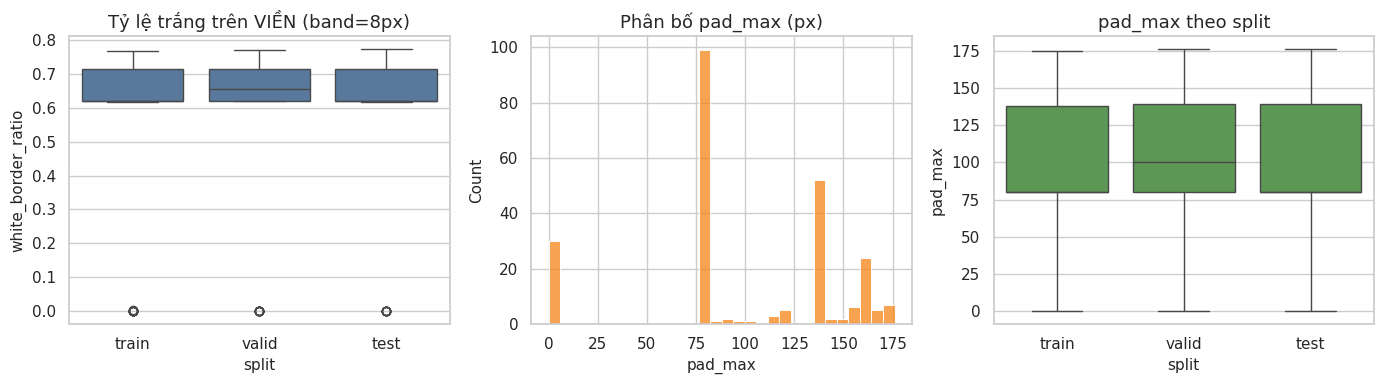

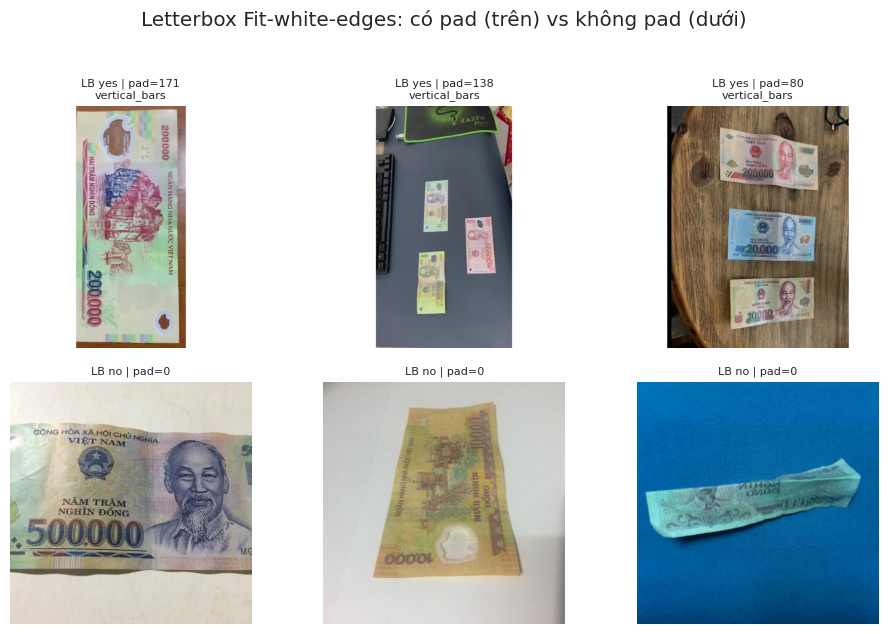

Nhận xét: letterbox là artifact tiền xử lý, không phải đặc trưng tờ tiền. Khi phân tích lỗi sau này, cần kiểm tra FP trên vùng viền trắng.


In [ ]:
def letterbox_stats(image_path: str, white_thr: int = 250, edge_band: int = 8, row_thr: float = 0.95):
    """Đo artifact letterbox sau Resize Fit (white edges).

    Trả về:
      - white_full_ratio / white_border_ratio
      - pad_top/bottom/left/right: số hàng/cột trắng liên tiếp từ mép
      - likely_letterbox: True nếu có pad > 0 ở ít nhất một cạnh
    """
    im = np.asarray(Image.open(image_path).convert("RGB"))
    near_white = (
        (im[:, :, 0] >= white_thr)
        & (im[:, :, 1] >= white_thr)
        & (im[:, :, 2] >= white_thr)
    )
    full_ratio = float(near_white.mean())

    border = np.zeros_like(near_white, dtype=bool)
    border[:edge_band, :] = True
    border[-edge_band:, :] = True
    border[:, :edge_band] = True
    border[:, -edge_band:] = True
    border_ratio = float(near_white[border].mean()) if border.any() else 0.0

    row_white = near_white.mean(axis=1)
    col_white = near_white.mean(axis=0)

    pad_top = 0
    while pad_top < len(row_white) and row_white[pad_top] >= row_thr:
        pad_top += 1
    pad_bottom = 0
    while pad_bottom < len(row_white) and row_white[-(pad_bottom + 1)] >= row_thr:
        pad_bottom += 1
    pad_left = 0
    while pad_left < len(col_white) and col_white[pad_left] >= row_thr:
        pad_left += 1
    pad_right = 0
    while pad_right < len(col_white) and col_white[-(pad_right + 1)] >= row_thr:
        pad_right += 1

    pad_max = max(pad_top, pad_bottom, pad_left, pad_right)
    likely = pad_max > 0
    orientation = (
        "vertical_bars" if (pad_left + pad_right) >= (pad_top + pad_bottom) else "horizontal_bars"
    )
    return {
        "white_full_ratio": full_ratio,
        "white_border_ratio": border_ratio,
        "pad_top": pad_top,
        "pad_bottom": pad_bottom,
        "pad_left": pad_left,
        "pad_right": pad_right,
        "pad_max": pad_max,
        "likely_letterbox": likely,
        "letterbox_orientation": orientation if likely else "none",
    }


# Lấy mẫu theo từng split để EDA nhanh
sample_imgs = pd.concat([
    df_img[df_img["split"] == s].sample(
        n=min(80, int((df_img["split"] == s).sum())),
        random_state=RANDOM_SEED,
    )
    for s in split_order
], ignore_index=True)

lb_rows = []
for _, r in sample_imgs.iterrows():
    st = letterbox_stats(r["image_path"])
    lb_rows.append({
        "split": r["split"],
        "image": r["image"],
        "image_path": r["image_path"],
        **st,
    })

df_lb = pd.DataFrame(lb_rows)
lb_summary = (
    df_lb.groupby("split", as_index=False)
         .agg(
             n_sample=("image", "count"),
             mean_white_full=("white_full_ratio", "mean"),
             mean_white_border=("white_border_ratio", "mean"),
             mean_pad_max=("pad_max", "mean"),
             pct_likely_letterbox=("likely_letterbox", lambda s: 100 * float(s.mean())),
         )
)
lb_summary["split"] = pd.Categorical(lb_summary["split"], categories=split_order, ordered=True)
lb_summary = lb_summary.sort_values("split")

print(f"Đã đo letterbox trên {len(df_lb)} ảnh mẫu")
display(lb_summary.round(3))
print("Hướng letterbox (trên mẫu có pad):")
display(
    df_lb[df_lb["likely_letterbox"]]["letterbox_orientation"]
      .value_counts(dropna=False)
      .rename_axis("orientation")
      .reset_index(name="n")
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(
    data=df_lb, x="split", y="white_border_ratio",
    order=split_order, ax=axes[0], color="#4C78A8",
)
axes[0].set_title("Tỷ lệ trắng trên VIỀN (band=8px)")
axes[0].set_ylabel("white_border_ratio")

sns.histplot(df_lb["pad_max"], bins=30, ax=axes[1], color="#F58518")
axes[1].set_title("Phân bố pad_max (px)")
axes[1].set_xlabel("pad_max")

sns.boxplot(
    data=df_lb, x="split", y="pad_max",
    order=split_order, ax=axes[2], color="#54A24B",
)
axes[2].set_title("pad_max theo split")
plt.tight_layout()
plt.show()

n_yes = int(df_lb["likely_letterbox"].sum())
n_no = int((~df_lb["likely_letterbox"]).sum())
show_n = min(3, n_yes, max(n_no, 1))
fig, axes = plt.subplots(2, show_n, figsize=(3.2 * show_n, 6.2))
axes = np.array(axes).reshape(2, show_n)

yes_rows = df_lb[df_lb["likely_letterbox"]].head(show_n)
no_rows = df_lb[~df_lb["likely_letterbox"]].head(show_n)

for j, (_, r) in enumerate(yes_rows.iterrows()):
    axes[0, j].imshow(Image.open(r["image_path"]))
    axes[0, j].set_title(
        f"LB yes | pad={int(r['pad_max'])}\n{r['letterbox_orientation']}",
        fontsize=8,
    )
    axes[0, j].axis("off")

if len(no_rows) == 0:
    for j in range(show_n):
        axes[1, j].axis("off")
        axes[1, j].set_title("LB no: không có trong mẫu", fontsize=8)
else:
    for j, (_, r) in enumerate(no_rows.iterrows()):
        axes[1, j].imshow(Image.open(r["image_path"]))
        axes[1, j].set_title(f"LB no | pad={int(r['pad_max'])}", fontsize=8)
        axes[1, j].axis("off")
    for j in range(len(no_rows), show_n):
        axes[1, j].axis("off")

plt.suptitle("Letterbox Fit-white-edges: có pad (trên) vs không pad (dưới)", y=1.02)
plt.tight_layout()
plt.show()

print(
    "Nhận xét: letterbox là artifact tiền xử lý, không phải đặc trưng tờ tiền. "
    "Khi phân tích lỗi sau này, cần kiểm tra FP trên vùng viền trắng."
)


## 15. Phát hiện outlier hình học của box

Với biến số/hình học, cần xem phân phối và ngoại lệ trước khi đưa vào học.  
Box quá nhỏ, quá lớn hoặc tỷ lệ khung hình bất thường có thể là **nhãn lệch**, object bị cắt mạnh, hoặc điều kiện chụp cực đoan — đều đáng QA thủ công.


,loại outlier,n_boxes,pct
0,area ≤ P01 (0.0058),56,1.02
1,area ≥ P99 (0.7445),55,1.01
2,"aspect_ratio ngoài [P01,P99]=[0.355,3.084]",110,2.01
3,bất kỳ (union),170,3.11


Outlier theo class:


,class_name,n_outlier_boxes
1,10000,71
8,500000,35
5,200000,25
4,20000,21
0,1000,6
6,5000,4
2,100000,3
3,2000,3
7,50000,2


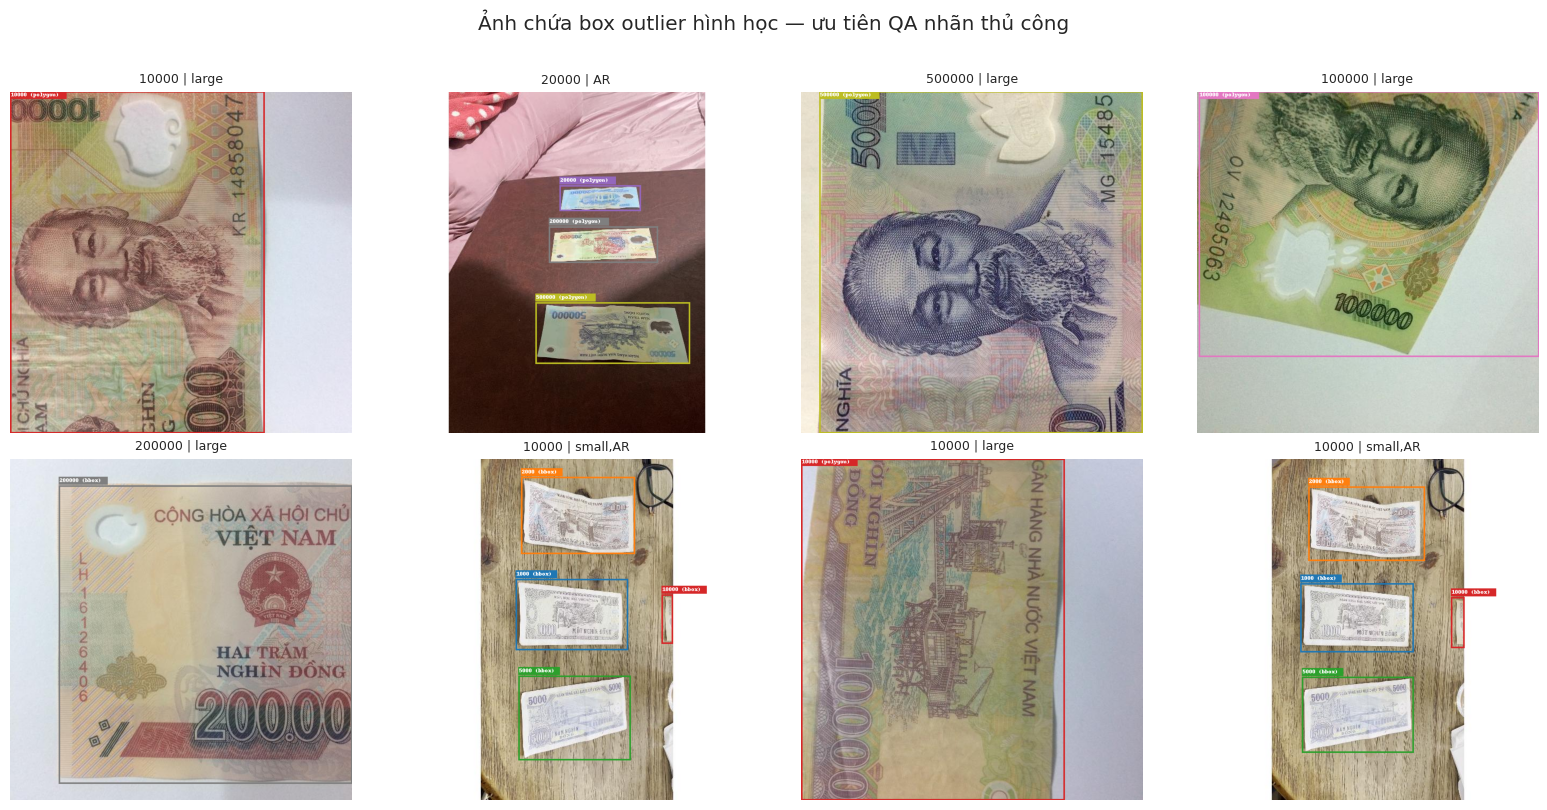

Các box outlier nên được rà soát thủ công: có thể là nhãn lệch, object bị cắt, hoặc điều kiện chụp cực đoan nhưng vẫn hợp lệ.


In [ ]:
# Tính / cập nhật geo cho phân tích outlier
geo = df_obj.copy()
geo["area_norm"] = geo["w"] * geo["h"]
geo["aspect_ratio"] = geo["w"] / geo["h"].replace(0, np.nan)
geo["box_w_px"] = geo["w"] * geo["img_w"]
geo["box_h_px"] = geo["h"] * geo["img_h"]

q_area = geo["area_norm"].quantile([0.01, 0.99]).to_dict()
q_ar = geo["aspect_ratio"].quantile([0.01, 0.99]).to_dict()

geo["outlier_small"] = geo["area_norm"] <= q_area[0.01]
geo["outlier_large"] = geo["area_norm"] >= q_area[0.99]
geo["outlier_ar"] = (geo["aspect_ratio"] <= q_ar[0.01]) | (geo["aspect_ratio"] >= q_ar[0.99])
geo["is_geom_outlier"] = geo["outlier_small"] | geo["outlier_large"] | geo["outlier_ar"]

outlier_summary = pd.DataFrame({
    "loại outlier": [
        f"area ≤ P01 ({q_area[0.01]:.4f})",
        f"area ≥ P99 ({q_area[0.99]:.4f})",
        f"aspect_ratio ngoài [P01,P99]=[{q_ar[0.01]:.3f},{q_ar[0.99]:.3f}]",
        "bất kỳ (union)",
    ],
    "n_boxes": [
        int(geo["outlier_small"].sum()),
        int(geo["outlier_large"].sum()),
        int(geo["outlier_ar"].sum()),
        int(geo["is_geom_outlier"].sum()),
    ],
})
outlier_summary["pct"] = (100 * outlier_summary["n_boxes"] / len(geo)).round(2)
display(outlier_summary)

print("Outlier theo class:")
display(
    geo[geo["is_geom_outlier"]]
      .groupby("class_name", as_index=False)
      .size()
      .rename(columns={"size": "n_outlier_boxes"})
      .sort_values("n_outlier_boxes", ascending=False)
)

out_imgs = geo.loc[geo["is_geom_outlier"], "image"].drop_duplicates()
out_samples = out_imgs.sample(n=min(8, len(out_imgs)), random_state=RANDOM_SEED)

cols = 4
rows = int(np.ceil(len(out_samples) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
axes = np.array(axes).reshape(-1)

for ax, img_name in zip(axes, out_samples):
    ann = df[df["image"] == img_name]
    ip = df_img.loc[df_img["image"] == img_name, "image_path"].iloc[0]
    vis = draw_boxes(ip, ann)
    flags_row = geo[(geo["image"] == img_name) & (geo["is_geom_outlier"])].iloc[0]
    flags = []
    if flags_row["outlier_small"]:
        flags.append("small")
    if flags_row["outlier_large"]:
        flags.append("large")
    if flags_row["outlier_ar"]:
        flags.append("AR")
    ax.imshow(vis)
    ax.set_title(f"{flags_row['class_name']} | {','.join(flags)}", fontsize=9)
    ax.axis("off")

for ax in axes[len(out_samples):]:
    ax.axis("off")

plt.suptitle("Ảnh chứa box outlier hình học — ưu tiên QA nhãn thủ công", y=1.01)
plt.tight_layout()
plt.show()

print(
    "Các box outlier nên được rà soát thủ công: có thể là nhãn lệch, "
    "object bị cắt, hoặc điều kiện chụp cực đoan nhưng vẫn hợp lệ."
)


## 16. Thống nhất định dạng nhãn trước khi học

Dataset đang **lẫn bbox và polygon**. Mục tiêu hiện tại là **object detection**, nên mọi nhãn cần quy về bbox thống nhất.

Cell dưới minh họa bước chuyển đổi (không ghi đè bản gốc) và kiểm tra bbox bao quanh polygon có hợp lý không.


Trước khi thống nhất: {'bbox': 3810, 'polygon': 1654}

=== 006769ea-071e-43ea-9165-7ed6cee7b9d6_jpg.rf.a0a4d342676236ae61180a53441308e8.jpg (train) ===
RAW   : 8 0.5917622625213586 1 0.7801753964975024 0.22280781812082934 0.447111070421007 0.11600000169542099 0.2451531454064208 0...
BBOX  : 8 0.512664 0.558000 0.535022 0.884000

=== 014bce1a-c772-4522-8cb9-c0f58047a815_jpg.rf.d852a436c6b400d2ccbcf620634af0fe.jpg (train) ===
RAW   : 5 0.9597012528254527 0.672717722530461 0.8868243556097909 0.31883604909252006 0.06562742468963431 0.432647212937999 0.11...
BBOX  : 5 0.512664 0.569576 0.894074 0.501481

=== 02890660-7b1b-4cbf-a919-143160d5e225_jpg.rf.f3aa5ef9a676913b9a4b9c494f9c4211.jpg (train) ===
RAW   : 5 0.959423448614752 0.7162304712393638 0.9754209552149927 0.26809882280689046 0.043666636149088625 0.3070000012715658 0....
BBOX  : 5 0.506832 0.492165 0.937178 0.448132


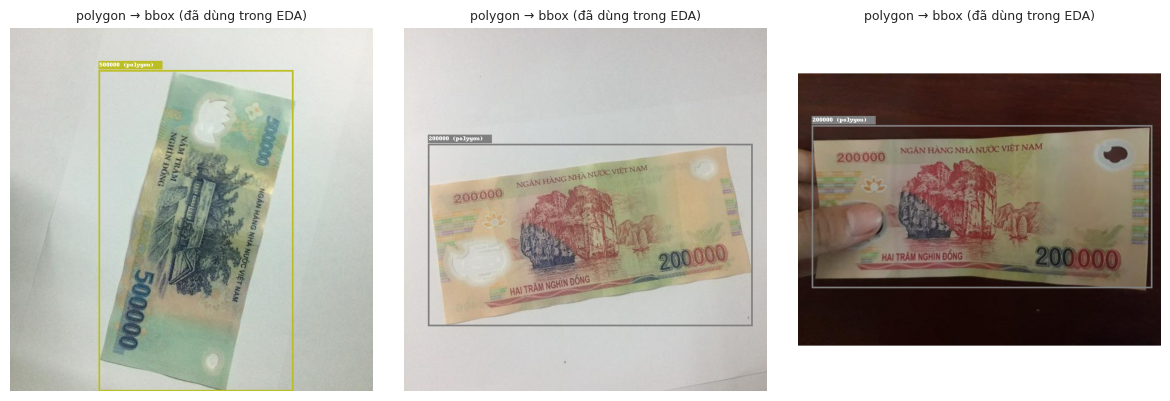


Hướng xử lý tiếp theo: tạo bản dữ liệu bbox thống nhất (giữ bản gốc để truy vết), rồi dùng bản đó cho mọi bước huấn luyện detection.


In [ ]:
def polygon_line_to_bbox_line(line: str) -> str:
    """YOLO polygon/bbox line → YOLO bbox line (xc yc w h)."""
    obj = parse_yolo_line(line)
    return (
        f'{obj["class_id"]} {obj["xc"]:.6f} {obj["yc"]:.6f} '
        f'{obj["w"]:.6f} {obj["h"]:.6f}'
    )


fmt_before = df_obj["ann_type"].value_counts().to_dict()
print("Trước khi thống nhất:", fmt_before)

poly_files = (
    df_obj[df_obj["ann_type"] == "polygon"][["split", "image", "label_path", "image_path"]]
      .drop_duplicates()
      .head(3)
)

for _, r in poly_files.iterrows():
    raw = Path(r["label_path"]).read_text(encoding="utf-8").splitlines()
    raw = [ln for ln in raw if ln.strip()]
    converted = [polygon_line_to_bbox_line(ln) for ln in raw]
    print("\n===", r["image"], f"({r['split']}) ===")
    preview = raw[0][:120] + ("..." if len(raw[0]) > 120 else "")
    print("RAW   :", preview)
    print("BBOX  :", converted[0])

if len(poly_files) > 0:
    n = min(3, len(poly_files))
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes = np.array(axes).reshape(-1)
    for ax, (_, r) in zip(axes, poly_files.iterrows()):
        ann = df[df["image"] == r["image"]]
        ax.imshow(draw_boxes(r["image_path"], ann))
        ax.set_title("polygon → bbox (đã dùng trong EDA)", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

print(
    "\nHướng xử lý tiếp theo: tạo bản dữ liệu bbox thống nhất (giữ bản gốc để truy vết), "
    "rồi dùng bản đó cho mọi bước huấn luyện detection."
)


## 17. Chốt phạm vi lớp mục tiêu

Đề bài kỳ vọng 10 mệnh giá, trong khi `data.yaml` chỉ có 9 lớp (thiếu `500`).  
Đây là câu hỏi phải trả lời **trước khi chọn mô hình**: thu hẹp phạm vi cho khớp dữ liệu, hoặc bổ sung dữ liệu cho đủ lớp.


In [ ]:
expected_readme = [
    "500", "1000", "2000", "5000", "10000",
    "20000", "50000", "100000", "200000", "500000",
]
missing_classes = [c for c in expected_readme if c not in CLASS_NAMES]
present_sorted = sorted(CLASS_NAMES, key=lambda x: int(x))

coverage = pd.DataFrame({
    "mệnh_giá": expected_readme,
    "có_trong_dataset": [c in CLASS_NAMES for c in expected_readme],
    "n_boxes": [
        int((df_obj["class_name"] == c).sum()) if c in CLASS_NAMES else 0
        for c in expected_readme
    ],
})
display(coverage)

print("Class hiện có :", present_sorted)
print("Class thiếu   :", missing_classes)

print(
    "\nHàm ý cho bước model hóa:\n"
    "  - Hoặc thu hẹp bài toán đúng 9 lớp đang có,\n"
    "  - Hoặc bổ sung dữ liệu/nhãn cho lớp 500 trước khi train bản cuối.\n"
    "Không nên tuyên bố 10 lớp trong khi thực nghiệm chỉ có 9 lớp."
)


,mệnh_giá,có_trong_dataset,n_boxes
0,500,False,0
1,1000,True,604
2,2000,True,607
3,5000,True,609
4,10000,True,609
5,20000,True,603
6,50000,True,620
7,100000,True,609
8,200000,True,602
9,500000,True,601


Class hiện có : ['1000', '2000', '5000', '10000', '20000', '50000', '100000', '200000', '500000']
Class thiếu   : ['500']

Hàm ý cho bước model hóa:
  - Hoặc thu hẹp bài toán đúng 9 lớp đang có,
  - Hoặc bổ sung dữ liệu/nhãn cho lớp 500 trước khi train bản cuối.
Không nên tuyên bố 10 lớp trong khi thực nghiệm chỉ có 9 lớp.


## 18. Nguyên tắc chia dữ liệu và tránh rò rỉ thông tin

Để đánh giá khách quan, mọi lựa chọn (augment, early-stop, ngưỡng tin cậy, cấu hình model) chỉ dựa trên **train/valid**.  
Tập **test** giữ độc lập đến bước đánh giá cuối, tránh làm “đẹp giả” các chỉ số tổng quát hóa.


In [ ]:
leakage_checklist = pd.DataFrame([
    {
        "hạng mục": "Split cố định train/valid/test từ Roboflow",
        "trạng thái": "OK — đang dùng 3 thư mục sẵn có",
        "rủi ro nếu sai": "So sánh model không công bằng",
    },
    {
        "hạng mục": "Không dùng test để early-stop / chọn conf threshold",
        "trạng thái": "QUY TẮC nhóm — chỉ tune trên valid",
        "rủi ro nếu sai": "Metric test lạc quan giả",
    },
    {
        "hạng mục": "Không train lại trên test rồi báo điểm test",
        "trạng thái": "QUY TẮC nhóm",
        "rủi ro nếu sai": "Không còn tập đánh giá độc lập",
    },
    {
        "hạng mục": "Augmentation chỉ áp khi train (không pre-bake vào valid/test)",
        "trạng thái": "README Roboflow: no augmentation khi export",
        "rủi ro nếu sai": "Val/test không phản ánh ảnh thật",
    },
    {
        "hạng mục": "Preprocess letterbox nhất quán cả 3 split",
        "trạng thái": "OK nếu nhất quán; ghi nhận artifact",
        "rủi ro nếu sai": "Train/test khác phân phối tiền xử lý",
    },
    {
        "hạng mục": "EDA trên test chỉ để mô tả, không để chọn model",
        "trạng thái": "Cho phép mô tả; quyết định model dựa val",
        "rủi ro nếu sai": "Lựa chọn bị ảnh hưởng bởi test",
    },
])
display(leakage_checklist)

print(
    f"Nhắc lại quy mô split: train={int((df_img.split=='train').sum())}, "
    f"valid={int((df_img.split=='valid').sum())}, "
    f"test={int((df_img.split=='test').sum())}"
)
print("Thực hành đánh giá: chọn cấu hình trên VALID; chỉ chạy đánh giá cuối trên TEST một lần.")


,hạng mục,trạng thái,rủi ro nếu sai
0,Split cố định train/valid/test từ Roboflow,OK — đang dùng 3 thư mục sẵn có,So sánh model không công bằng
1,Không dùng test để early-stop / chọn conf thre...,QUY TẮC nhóm — chỉ tune trên valid,Metric test lạc quan giả
2,Không train lại trên test rồi báo điểm test,QUY TẮC nhóm,Không còn tập đánh giá độc lập
3,Augmentation chỉ áp khi train (không pre-bake ...,README Roboflow: no augmentation khi export,Val/test không phản ánh ảnh thật
4,Preprocess letterbox nhất quán cả 3 split,OK nếu nhất quán; ghi nhận artifact,Train/test khác phân phối tiền xử lý
5,"EDA trên test chỉ để mô tả, không để chọn model",Cho phép mô tả; quyết định model dựa val,Lựa chọn bị ảnh hưởng bởi test


Nhắc lại quy mô split: train=1537, valid=439, test=218
Thực hành đánh giá: chọn cấu hình trên VALID; chỉ chạy đánh giá cuối trên TEST một lần.


## 19. Biểu diễn sơ bộ đặc trưng trên crop tờ tiền

Sau khi có box, mỗi tờ tiền có thể xem như một mẫu ảnh nhỏ.  
Ở bước này ta rút các đặc trưng dễ tính từ pixel — **màu (HSV)** và **texture thô (độ lệch xám, mật độ cạnh)** — rồi so sánh phân phối theo mệnh giá.

Mục đích: hiểu lớp nào tách được bằng tín hiệu đơn giản, lớp nào chồng lấn (gợi ý cần biểu diễn mạnh hơn / mô hình sâu hơn ở bước sau).  
Phần khảo sát dùng mẫu **train/valid**; không dùng test để chọn đặc trưng.


In [ ]:
def crop_from_yolo(image_path, xc, yc, w, h, min_side=8):
    im = Image.open(image_path).convert("RGB")
    img_w, img_h = im.size
    x1, y1, x2, y2 = yolo_to_xyxy(xc, yc, w, h, img_w, img_h)
    x1, y1 = max(0, int(np.floor(x1))), max(0, int(np.floor(y1)))
    x2, y2 = min(img_w, int(np.ceil(x2))), min(img_h, int(np.ceil(y2)))
    if x2 - x1 < min_side or y2 - y1 < min_side:
        return None
    return im.crop((x1, y1, x2, y2))


def rgb_to_hsv_np(rgb: np.ndarray):
    """rgb uint8 HxWx3 → H in [0,360), S,V in [0,1]."""
    arr = rgb.astype(np.float32) / 255.0
    r, g, b = arr[..., 0], arr[..., 1], arr[..., 2]
    maxc = arr.max(axis=-1)
    minc = arr.min(axis=-1)
    v = maxc
    s = np.where(maxc == 0, 0, (maxc - minc) / np.maximum(maxc, 1e-8))
    rc = (maxc - r) / np.maximum(maxc - minc, 1e-8)
    gc = (maxc - g) / np.maximum(maxc - minc, 1e-8)
    bc = (maxc - b) / np.maximum(maxc - minc, 1e-8)
    h = np.zeros_like(maxc)
    h = np.where((maxc == r) & (maxc != minc), (bc - gc), h)
    h = np.where((maxc == g) & (maxc != minc), 2.0 + (rc - bc), h)
    h = np.where((maxc == b) & (maxc != minc), 4.0 + (gc - rc), h)
    h = (h / 6.0) % 1.0
    return h * 360.0, s, v


def extract_crop_features(crop: Image.Image) -> dict:
    rgb = np.asarray(crop)
    gray = rgb.mean(axis=2)
    h, s, v = rgb_to_hsv_np(rgb)
    gy, gx = np.gradient(gray.astype(np.float32))
    edge = np.sqrt(gx ** 2 + gy ** 2)
    return {
        "mean_r": float(rgb[:, :, 0].mean()),
        "mean_g": float(rgb[:, :, 1].mean()),
        "mean_b": float(rgb[:, :, 2].mean()),
        "mean_h": float(h.mean()),
        "mean_s": float(s.mean()),
        "mean_v": float(v.mean()),
        "std_gray": float(gray.std()),
        "edge_density": float((edge > 15.0).mean()),
        "edge_mean": float(edge.mean()),
        "crop_aspect": float(crop.size[0] / max(crop.size[1], 1)),
        "crop_area_px": int(crop.size[0] * crop.size[1]),
    }


feat_source = df_obj[df_obj["split"].isin(["train", "valid"])].copy()
per_class_n = 40
pieces = []
for cls in denom_order:
    sub = feat_source[feat_source["class_name"] == cls]
    pieces.append(sub.sample(n=min(per_class_n, len(sub)), random_state=RANDOM_SEED))
feat_sample = pd.concat(pieces, ignore_index=True)

feat_rows = []
for _, r in feat_sample.iterrows():
    crop = crop_from_yolo(r["image_path"], r["xc"], r["yc"], r["w"], r["h"])
    if crop is None:
        continue
    feats = extract_crop_features(crop)
    feats.update({
        "split": r["split"],
        "image": r["image"],
        "class_name": r["class_name"],
        "area_norm": float(r["w"] * r["h"]),
    })
    feat_rows.append(feats)

df_feat = pd.DataFrame(feat_rows)
print(f"Đã trích feature từ {len(df_feat)} crop (mẫu train/valid)")
display(df_feat.head())
display(
    df_feat.groupby("class_name")[["mean_h", "mean_s", "mean_v", "std_gray", "edge_density"]]
          .mean()
          .round(3)
          .loc[denom_order]
)


Đã trích feature từ 360 crop (mẫu train/valid)


,mean_r,mean_g,mean_b,mean_h,mean_s,mean_v,std_gray,edge_density,edge_mean,crop_aspect,crop_area_px,split,image,class_name,area_norm
0,202.785389,197.054664,184.591823,64.378799,0.104184,0.795647,36.118343,0.271170,12.019008,1.869565,15824,train,5212670_jpg.rf.14ffa4945f530464bafa94d847c5a2c...,1000,0.038633
1,202.692477,196.747106,184.048322,62.119099,0.107300,0.795292,37.325546,0.321528,13.298030,1.875000,17280,train,5212718_jpg.rf.11abd8755188810546c0278e554ff82...,1000,0.041748
2,202.977529,197.384824,185.096070,65.152237,0.103216,0.796492,37.678904,0.336463,13.770149,1.918367,18424,train,5212786_jpg.rf.745af2fb2a0a1a1e7d58a749211241f...,1000,0.044521
3,179.617460,176.221465,159.375108,52.514385,0.135562,0.708707,46.312589,0.381602,16.721724,1.925000,27720,train,IMG_7540_jpeg.rf.f451c600cbb1c08a448c838cb34eb...,1000,0.066815
4,198.994249,192.555225,178.590840,59.366909,0.121031,0.780957,39.666108,0.359548,14.613526,1.863636,14432,train,5212582_jpg.rf.9952333d6c0af1325c483ebc27429b1...,1000,0.035020


,mean_h,mean_s,mean_v,std_gray,edge_density
class_name,,,,,
1000,111.654,0.201,0.721,40.893,0.327
2000,116.261,0.197,0.711,41.273,0.374
5000,155.560,0.235,0.728,41.465,0.307
10000,69.780,0.216,0.669,37.716,0.226
20000,144.757,0.222,0.657,38.149,0.234
50000,195.378,0.204,0.637,44.820,0.196
100000,99.016,0.220,0.594,41.237,0.235
200000,93.723,0.244,0.630,39.822,0.208
500000,131.068,0.178,0.671,42.063,0.192


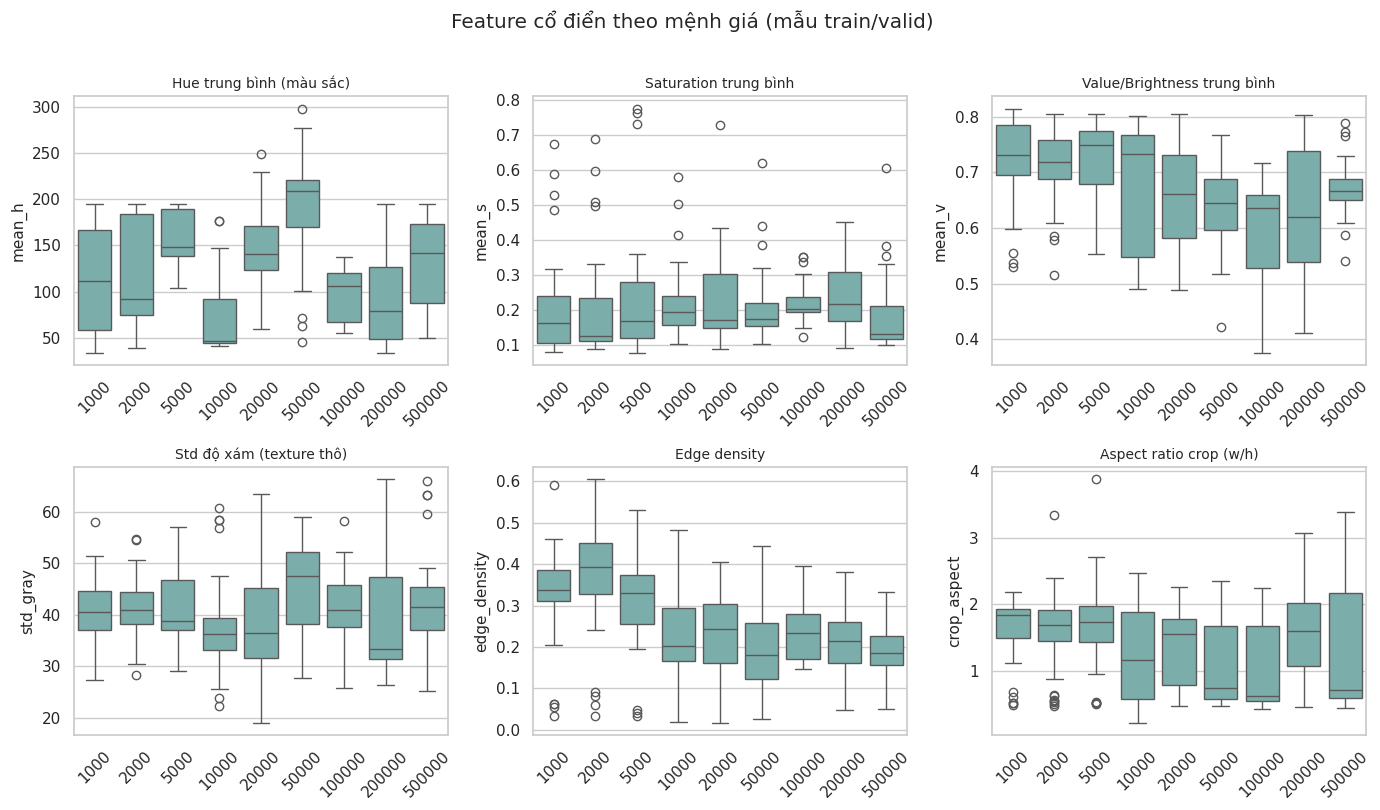

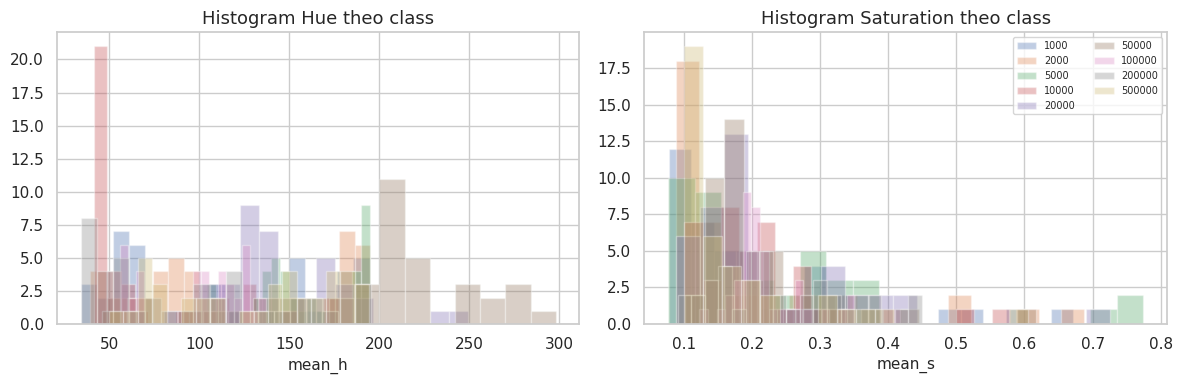

Nếu phân phối màu/texture tách lớp khá rõ, có thể thử bộ phân lớp trên đặc trưng thủ công. Nếu các lớp chồng lấn mạnh, cần biểu diễn mạnh hơn (ví dụ mô hình detection học đặc trưng từ ảnh).
Đã lưu: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/eda_exports/crop_features_sample.csv


In [ ]:
plot_vars = [
    ("mean_h", "Hue trung bình (màu sắc)"),
    ("mean_s", "Saturation trung bình"),
    ("mean_v", "Value/Brightness trung bình"),
    ("std_gray", "Std độ xám (texture thô)"),
    ("edge_density", "Edge density"),
    ("crop_aspect", "Aspect ratio crop (w/h)"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, (col, title) in zip(axes, plot_vars):
    sns.boxplot(
        data=df_feat, x="class_name", y=col,
        order=denom_order, ax=ax, color="#72B7B2",
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.suptitle("Feature cổ điển theo mệnh giá (mẫu train/valid)", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls in denom_order:
    sub = df_feat[df_feat["class_name"] == cls]
    axes[0].hist(sub["mean_h"], bins=18, alpha=0.35, label=cls)
    axes[1].hist(sub["mean_s"], bins=18, alpha=0.35, label=cls)
axes[0].set_title("Histogram Hue theo class")
axes[1].set_title("Histogram Saturation theo class")
axes[0].set_xlabel("mean_h")
axes[1].set_xlabel("mean_s")
axes[1].legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout()
plt.show()

print(
    "Nếu phân phối màu/texture tách lớp khá rõ, có thể thử bộ phân lớp trên đặc trưng thủ công. "
    "Nếu các lớp chồng lấn mạnh, cần biểu diễn mạnh hơn (ví dụ mô hình detection học đặc trưng từ ảnh)."
)

feat_out = PROJECT_DIR / "notebooks" / "eda_exports"
feat_out.mkdir(parents=True, exist_ok=True)
df_feat.to_csv(feat_out / "crop_features_sample.csv", index=False)
print("Đã lưu:", feat_out / "crop_features_sample.csv")


## 20. Tóm tắt nhận xét sau EDA

Phần này đóng vai trò “hồ sơ dữ liệu” trước khi sang huấn luyện: quy mô, phân phối, rủi ro chất lượng, phạm vi lớp, và hàm ý cho pipeline model.


In [ ]:
summary = {
    "n_images": int(len(df_img)),
    "n_objects": int(df_obj.shape[0]),
    "n_classes": int(NC),
    "classes": CLASS_NAMES,
    "split_counts": df_img["split"].value_counts().to_dict(),
    "mean_objects_per_image": float(df_img["n_objects"].mean()),
    "pct_multi_object_images": float(100 * (df_img["n_objects"] >= 2).mean()),
    "pct_polygon_labels": float(100 * (df_obj["ann_type"] == "polygon").mean()),
    "pct_bbox_labels": float(100 * (df_obj["ann_type"] == "bbox").mean()),
    "image_size_unique": df_img.groupby(["img_w", "img_h"]).ngroups,
    "class_balance_ratio_max_min": float(
        class_overall["n_boxes"].max() / max(class_overall["n_boxes"].min(), 1)
    ),
    "n_geom_outliers": int(geo["is_geom_outlier"].sum()) if "is_geom_outlier" in geo.columns else None,
    "pct_likely_letterbox_sample": (
        float(100 * df_lb["likely_letterbox"].mean()) if "df_lb" in globals() else None
    ),
    "n_crop_features_sampled": int(len(df_feat)) if "df_feat" in globals() else None,
    "missing_vs_readme": missing_classes if "missing_classes" in globals() else ["500"],
}

for k, v in summary.items():
    print(f"{k:32s}: {v}")

print("\n--- Nhận xét tổng hợp sau EDA ---")
print(
    f"1) Bộ dữ liệu gồm {summary['n_images']} ảnh, {summary['n_objects']} object, "
    f"{summary['n_classes']} class mệnh giá."
)
print(f"2) Tỷ lệ split: {summary['split_counts']}.")
print(
    f"3) Trung bình ~{summary['mean_objects_per_image']:.2f} tờ tiền / ảnh; "
    f"~{summary['pct_multi_object_images']:.1f}% ảnh có ≥ 2 object."
)
print(
    f"4) Phân bố class khá cân bằng "
    f"(max/min ≈ {summary['class_balance_ratio_max_min']:.2f})."
)
print(
    f"5) Nhãn lẫn bbox ({summary['pct_bbox_labels']:.1f}%) và "
    f"polygon ({summary['pct_polygon_labels']:.1f}%); cần thống nhất bbox trước train."
)
print("6) Thiếu class 500đ so với README — thu hẹp đề bài hoặc bổ sung dữ liệu.")
print("7) Resize Fit white edges → letterbox; lưu ý FP trên nền trắng khi phân tích lỗi.")
print("8) Đã tách đơn vị quan sát ảnh vs object; đã khảo sát đặc trưng màu/texture trên crop.")
print("9) Giữ test độc lập: mọi lựa chọn cấu hình chỉ dựa train/valid.")


n_images                        : 2194
n_objects                       : 5464
n_classes                       : 9
classes                         : ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']
split_counts                    : {'train': 1537, 'valid': 439, 'test': 218}
mean_objects_per_image          : 2.4904284412032816
pct_multi_object_images         : 58.75113947128532
pct_polygon_labels              : 30.27086383601757
pct_bbox_labels                 : 69.72913616398243
image_size_unique               : 1
class_balance_ratio_max_min     : 1.0316139767054908
n_geom_outliers                 : 170
pct_likely_letterbox_sample     : 87.5
n_crop_features_sampled         : 360
missing_vs_readme               : ['500']

--- Nhận xét tổng hợp sau EDA ---
1) Bộ dữ liệu gồm 2194 ảnh, 5464 object, 9 class mệnh giá.
2) Tỷ lệ split: {'train': 1537, 'valid': 439, 'test': 218}.
3) Trung bình ~2.49 tờ tiền / ảnh; ~58.8% ảnh có ≥ 2 object.
4) Phân bố class khá câ

## 21. (Tuỳ chọn) Xuất bảng thống kê ra CSV

Lưu các bảng EDA để dùng lại khi viết báo cáo hoặc so sánh giữa các phiên bản dữ liệu.


In [ ]:
OUT_DIR = PROJECT_DIR / "notebooks" / "eda_exports"
OUT_DIR.mkdir(parents=True, exist_ok=True)

split_summary.to_csv(OUT_DIR / "split_summary.csv", index=False)
class_overall.to_csv(OUT_DIR / "class_distribution.csv", index=False)
obj_count_dist.to_csv(OUT_DIR / "objects_per_image.csv", index=False)
ann_summary.to_csv(OUT_DIR / "annotation_types.csv", index=False)
issues_df.to_csv(OUT_DIR / "qa_checks.csv", index=False)

if "outlier_summary" in globals():
    outlier_summary.to_csv(OUT_DIR / "geom_outlier_summary.csv", index=False)
    geo.loc[
        geo["is_geom_outlier"],
        [
            "split", "image", "class_name", "area_norm", "aspect_ratio",
            "outlier_small", "outlier_large", "outlier_ar",
        ],
    ].to_csv(OUT_DIR / "geom_outliers_detail.csv", index=False)

if "lb_summary" in globals():
    lb_summary.to_csv(OUT_DIR / "letterbox_summary.csv", index=False)

if "leakage_checklist" in globals():
    leakage_checklist.to_csv(OUT_DIR / "leakage_checklist.csv", index=False)

if "coverage" in globals():
    coverage.to_csv(OUT_DIR / "class_coverage_vs_readme.csv", index=False)

print("Đã lưu CSV tại:", OUT_DIR)


Đã lưu CSV tại: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/notebooks/eda_exports
